# Dense MLP、通常学習 TT-MLP、DMRG-like TT-MLP の比較

この Notebook が扱う問いは次である。

> TT 圧縮と DMRG-like 学習によって、Dense MLP に近い分類性能を、どれだけ少ない parameter 数で実現できたか。その代償として理論 MACs、推論 latency、学習コストはどう変わったか。同じ TT 表現を通常の Adam で学習した場合と比べて、DMRG-like 学習にはどのような違いがあるか。

parameter 数の削減は、TT 表現と rank 制約から来る。DMRG-like は、その圧縮表現を学習する最適化方法である。圧縮したこと自体を、推論が速くなったという結論にはしない。

現在の `tt_linear_forward` は、左から右へ `torch.tensordot` する。この縮約では、同じ入出力次元でも site ごとの中間次元が残る。したがって parameter 数が減ることと、理論 MACs が減ることは別である。この設定の式から計算される TT fc1 は 2,175,488 MACs/sample、Dense fc1 は 401,408 MACs/sample である。実測 latency は、この式とは別に測る。

## 比較する学習手順

- Dense MLP: `MNISTMLP`。784、512、256、10。ReLU は fc1 と fc2 の後。Adam、学習率 `1e-3`、batch 64。
- 通常学習 TT-MLP: Stage C から、全 TT core と fc1.bias、fc2、fc3 を Adam で end-to-end 学習する。rank と core shape は変えない。
- DMRG-like joint: Notebook 05 の joint を、同じ全データ更新のまま続ける。TT 側も Dense 側も学習率 0.3、batch 4,096、GPU 常駐。

通常 TT と DMRG-like は、optimizer、batch の単位、更新経路が違う。この対比は、選んだ学習手順全体の比較である。局所化や SVD だけを切り分けた因果比較ではない。full-batch GD の対照は足さない。

## データの役割

- train 50,000: 学習
- early-stopping validation 5,000: strict best の選択と停止判定
- rank-selection validation 5,000: 学習終了後、best checkpoint だけの最終比較
- test: 長さ以外は見ない

損失は平均 cross-entropy である。

## 実行スイッチ

`RUN_SMOKE` と `RUN_MAIN_EXPERIMENT` は既定で偽である。このファイルを上から実行しても、学習は始まらない。結果の保存先は 06 のディレクトリだけである。

## この段階で言えること、言えないこと

言えるのは、比較の定義と、式から決まる計算量の区別である。学習が終わる前に、精度の優劣、latency の大小、収束したかどうかは書かない。

- 単一 seed の結果は、一般化した優劣ではない。
- early stopping は、数学的収束や大域最適解を意味しない。
- 上限へ達した停止は `max_epochs` または `max_sweeps` であり、収束済みとは呼ばない。
- test は使わない。
- 学習率は、方式ごとに個別最適化した値ではない。
- 理論 MACs と実測 latency は別の量である。

In [45]:
from pathlib import Path
import csv
import hashlib
import json
import math
import os
import random
import shutil
import re
import subprocess
import sys
import time

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / ".git").exists() and (candidate / "src").exists():
        os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
        if str(candidate / "src") not in sys.path:
            sys.path.insert(0, str(candidate / "src"))
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("プロジェクトルートを特定できませんでした。")

from nn_compression.compression import TTLinear
from nn_compression.datasets import get_fashion_mnist_datasets, split_fashion_mnist_dataset
from nn_compression.metrics import (
    count_parameters,
    linear_macs,
    measure_synchronized_inference_latency,
    tt_linear_direct_contraction_macs,
)
from nn_compression.models import MNISTMLP
from nn_compression.training import (
    GpuResidentTensorBatches,
    TTUpdateScope,
    evaluate,
    initial_validation_selection,
    load_tt_linear_sweep_checkpoint,
    replay_validation_selection,
    train_one_epoch,
    train_scoped_full_batch_budget,
    update_validation_selection,
)
from nn_compression.tt_mps import tt_matrix_canonicality_errors, tt_matrix_ranks
from nn_compression.utils import find_project_root, get_experiment_dirs

RUN_SMOKE = False
RUN_MAIN_EXPERIMENT = False
SAVE_RESULTS = True

SEED = 0
DTYPE = torch.float32
SPLIT_LENGTHS = (50_000, 5_000, 5_000)
N_TRAIN = 50_000
TARGET_LAYER = "fc1"
OUT_MODES = (4, 2, 2, 2, 4, 4)
IN_MODES = (2, 2, 2, 2, 7, 7)
RANK_CAP = 12
EXPECTED_ACTUAL_RANKS = (1, 8, 12, 12, 12, 12, 1)
MIN_DELTA = 1e-4
PATIENCE = 5

DENSE_OPTIMIZER = "Adam"
DENSE_LEARNING_RATE = 1e-3
DENSE_TRAIN_BATCH_SIZE = 64
DENSE_MAX_EPOCHS = 50

STANDARD_TT_OPTIMIZER = "Adam"
STANDARD_TT_LEARNING_RATE = 1e-3
STANDARD_TT_TRAIN_BATCH_SIZE = 64
STANDARD_TT_MAX_EPOCHS = 50

DMRG_TT_LEARNING_RATE = 0.3
DMRG_DENSE_LEARNING_RATE = 0.3
DMRG_BATCH_SIZE = 4096
DMRG_DATA_RESIDENCY = "gpu_resident"
LOCAL_STEPS_PER_PAIR = 8
UPDATES_PER_SWEEP = 80
NOTEBOOK05_COMPLETED_SWEEPS = 40
NOTEBOOK05_COMPLETED_UPDATES = 3_200
MAX_TOTAL_SWEEPS = 200
MAX_TOTAL_LOCAL_UPDATES = 16_000

VALIDATION_BATCH_SIZE = 512
DIAGNOSTIC_BATCH_SIZE = 512
LATENCY_BATCH_SIZES = (1, 4096)
LATENCY_WARMUP = 20
LATENCY_REPETITIONS = 100
CHECK_INDICES = (0, 511, 512, 4095, 4096, 49151, 49152, 49663, 49664, 49999)
EXPECTED_UPDATED_PARAMETERS = (
    "fc1.bias",
    "fc2.weight",
    "fc2.bias",
    "fc3.weight",
    "fc3.bias",
)
EXPECTED_DENSE_PARAMETERS = 535_818
EXPECTED_TT_PARAMETERS = 140_378
EXPECTED_TT_CORE_ELEMENTS = 5_968
EXPECTED_DENSE_MACS = 535_040
EXPECTED_TT_FC1_MACS = 2_175_488
EXPECTED_TT_MLP_MACS = 2_309_120

NOTEBOOK05_VALIDATION_LOSS = 0.34194087901115416
NOTEBOOK05_VALIDATION_ACCURACY = 0.8716
NOTEBOOK05_SPLIT_INDEX_SHA256 = (
    "aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98087503382c3372f913"
    "|12cf7fe6cc2cdbb43177107c8a30dffb86cc099386d61fa5f4f05fdb1795d360"
    "|a80ccd6c95a3aa08fcfb7a5a10ffc883344da48ec37ce605220f964cef14cb26"
)
NOTEBOOK05_IMAGE_SHA256 = "6a1fd0602db5a1066210a55375d18f9b12115269e7c6759f64504735f020d4d5"
NOTEBOOK05_LABEL_SHA256 = "6ead6f3f16028865d36fd3c8625eba751820bd8031265a3be03e206136a3c96c"
NOTEBOOK05_CHECKPOINT_SHA256 = "ef9d5afcbffc0cdad787bc7e17f230917ae7cfb780bd506f5a348ae38ce10c6a"
NOTEBOOK05_TRAINER_SHA256 = "69f465fb3772305e1222a303541611e4daf5acf9c9cf75e8457dd376612b1ba1"
REFERENCE_DENSE_ACCURACY = 0.8884

EXPERIMENT_NAME = "06_dense_tt_dmrg_like_convergence_comparison"
SMOKE_EXPERIMENT_NAME = "06_dense_tt_dmrg_like_convergence_comparison_smoke"
PROTECTED_NAMES = {
    "00_full_batch_two_core_sweep_training",
    "01_tt_initialization_scale_diagnostics",
    "02_full_batch_sweep_update_budget_grid",
    "02_full_batch_sweep_update_budget_grid_smoke",
    "02_full_batch_sweep_update_budget_grid_smoke_bs512",
    "03_joint_learning_rate_02_03_s40_l8",
    "03_joint_learning_rate_02_03_s40_l8_smoke",
    "04_full_batch_gradient_optimization_benchmark",
    "05_update_scope_ablation_gpu_resident",
    "05_update_scope_ablation_gpu_resident_smoke",
}
FINISHED_STOPS = {"early_stopping", "max_epochs", "max_sweeps"}
CONDITIONS = ("dense", "standard_tt", "dmrg_like")

project_root = find_project_root(Path.cwd())
if project_root != PROJECT_ROOT:
    raise RuntimeError("プロジェクトルートの特定が一致しません。")
INITIAL_CHECKPOINT = (
    project_root
    / "models"
    / "40_dmrg"
    / "10_fashion_mnist_mlp"
    / "01_tt_initialization_scale_diagnostics"
    / "initial_stage_c.pt"
)
NOTEBOOK05_JOINT = (
    project_root
    / "models"
    / "40_dmrg"
    / "10_fashion_mnist_mlp"
    / "05_update_scope_ablation_gpu_resident"
    / "joint"
)
REFERENCE_DENSE_CHECKPOINT = (
    project_root
    / "models"
    / "10_svd"
    / "20_fashion_mnist_mlp"
    / "03_mlp_svd_finetuning_using_src_corrected_rerun"
    / "baseline_same_run.pt"
)
SCOPED_MODULE = project_root / "src" / "nn_compression" / "training" / "tt_linear_scoped_update.py"
_, models_dir, results_dir = get_experiment_dirs(
    project_root, "40_dmrg", "10_fashion_mnist_mlp", EXPERIMENT_NAME
)
_, smoke_models_dir, smoke_results_dir = get_experiment_dirs(
    project_root, "40_dmrg", "10_fashion_mnist_mlp", SMOKE_EXPERIMENT_NAME
)


def assert_output_path(path):
    resolved = Path(path).resolve()
    allowed = {
        models_dir.resolve(),
        results_dir.resolve(),
        smoke_models_dir.resolve(),
        smoke_results_dir.resolve(),
    }
    if not any(resolved == root or root in resolved.parents for root in allowed):
        raise RuntimeError(f"06 の保存先の外です: {resolved}")
    text = resolved.as_posix()
    for name in PROTECTED_NAMES:
        if name in text:
            raise RuntimeError(f"既存実験の保存先へ書き込もうとしました: {resolved}")


for directory in (models_dir, results_dir, smoke_models_dir, smoke_results_dir):
    assert_output_path(directory)
    if directory.name in PROTECTED_NAMES or not directory.name.startswith("06_"):
        raise RuntimeError(f"保存先の名前が 06 専用ではありません: {directory}")

assert UPDATES_PER_SWEEP == 2 * (len(OUT_MODES) - 1) * LOCAL_STEPS_PER_PAIR
assert MAX_TOTAL_LOCAL_UPDATES == MAX_TOTAL_SWEEPS * UPDATES_PER_SWEEP
assert MAX_TOTAL_SWEEPS - NOTEBOOK05_COMPLETED_SWEEPS == 160
assert (MAX_TOTAL_SWEEPS - NOTEBOOK05_COMPLETED_SWEEPS) * UPDATES_PER_SWEEP == 12_800
assert math.prod(OUT_MODES) == 512
assert math.prod(IN_MODES) == 784

print("RUN_SMOKE:", RUN_SMOKE)
print("RUN_MAIN_EXPERIMENT:", RUN_MAIN_EXPERIMENT)
print("SAVE_RESULTS:", SAVE_RESULTS)
print("models:", models_dir)
print("results:", results_dir)
print("このセルは CUDA を初期化しません。")


RUN_SMOKE: False
RUN_MAIN_EXPERIMENT: True
SAVE_RESULTS: True
models: D:\dev\nn-compression-svd-dmrg\models\40_dmrg\10_fashion_mnist_mlp\06_dense_tt_dmrg_like_convergence_comparison
results: D:\dev\nn-compression-svd-dmrg\results\40_dmrg\10_fashion_mnist_mlp\06_dense_tt_dmrg_like_convergence_comparison
このセルは CUDA を初期化しません。


## 1. データと Stage C

分割は Notebook 05 と同じ seed と `split_fashion_mnist_dataset` である。index の SHA-256、学習画像、学習ラベルを計算し、05 の `run_state.json` に残っている値と照合する。一致しない場合は、別データとして学習を始めない。

test は `len` だけを見る。rank-selection の画像は、このセルでは積まない。index の checksum だけを作る。

Stage C は `initial_stage_c.pt` を読む。ここでも GPU へは移さない。

In [46]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def tensor_sha256(tensor):
    array = tensor.detach().contiguous().cpu().numpy()
    return hashlib.sha256(array.tobytes()).hexdigest()


def index_sha256(subset):
    indices = torch.tensor(list(subset.indices), dtype=torch.int64)
    return hashlib.sha256(indices.numpy().tobytes()).hexdigest()


def make_loader(dataset, batch_size, *, shuffle=False, generator=None):
    if shuffle and generator is None:
        generator = torch.Generator()
        generator.manual_seed(SEED)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator,
        drop_last=False,
        num_workers=0,
        pin_memory=False,
    )


np.random.seed(SEED)
torch.manual_seed(SEED)

train_full, test_dataset = get_fashion_mnist_datasets(project_root / "data", download=False)
train_dataset, early_stopping_dataset, rank_selection_dataset = split_fashion_mnist_dataset(
    train_full,
    SPLIT_LENGTHS,
    seed=SEED,
)
if (len(train_dataset), len(early_stopping_dataset), len(rank_selection_dataset)) != SPLIT_LENGTHS:
    raise RuntimeError("分割サイズが 50,000 / 5,000 / 5,000 ではありません。")
if len(test_dataset) != 10_000:
    raise RuntimeError("test の長さが 10,000 ではありません。中身は読みません。")

train_images = torch.stack([train_dataset[index][0] for index in range(len(train_dataset))])
train_labels = torch.tensor(
    [int(train_dataset[index][1]) for index in range(len(train_dataset))],
    dtype=torch.int64,
)
IMAGE_SHA256 = tensor_sha256(train_images)
LABEL_SHA256 = tensor_sha256(train_labels)
SPLIT_INDEX_SHA256 = "|".join(
    index_sha256(subset)
    for subset in (train_dataset, early_stopping_dataset, rank_selection_dataset)
)
if IMAGE_SHA256 != NOTEBOOK05_IMAGE_SHA256:
    raise RuntimeError("学習画像の checksum が Notebook 05 と一致しません。")
if LABEL_SHA256 != NOTEBOOK05_LABEL_SHA256:
    raise RuntimeError("学習ラベルの checksum が Notebook 05 と一致しません。")
if SPLIT_INDEX_SHA256 != NOTEBOOK05_SPLIT_INDEX_SHA256:
    raise RuntimeError("split index の checksum が Notebook 05 と一致しません。")
for index in CHECK_INDICES:
    image, label = train_dataset[index]
    if not torch.equal(train_images[index], image) or int(train_labels[index]) != int(label):
        raise RuntimeError(f"境界 sample {index} が subset と一致しません。")

for batch_size, expected_last in ((64, 16), (512, 336), (4096, 848)):
    sizes = [int(images.shape[0]) for images, _ in make_loader(train_dataset, batch_size)]
    if sum(sizes) != N_TRAIN or sizes[-1] != expected_last:
        raise RuntimeError(f"batch {batch_size} の端数が一致しません: {sizes[-1]}")

if file_sha256(INITIAL_CHECKPOINT) != NOTEBOOK05_CHECKPOINT_SHA256:
    raise RuntimeError("initial_stage_c.pt の SHA-256 が Notebook 05 の記録と一致しません。")
if file_sha256(SCOPED_MODULE) != NOTEBOOK05_TRAINER_SHA256:
    raise RuntimeError("DMRG-like の学習実装ファイルが Notebook 05 実行時と一致しません。")


def core_keys(state):
    prefix = f"{TARGET_LAYER}.cores."
    return sorted(
        (key for key in state if key.startswith(prefix)),
        key=lambda key: int(key.rsplit(".", 1)[-1]),
    )


def assert_stage_c(payload):
    if payload.get("layer_name") != TARGET_LAYER:
        raise ValueError(f"layer_name が一致しません: {payload.get('layer_name')!r}")
    if tuple(payload.get("out_modes", ())) != OUT_MODES:
        raise ValueError(f"out_modes が一致しません: {payload.get('out_modes')!r}")
    if tuple(payload.get("in_modes", ())) != IN_MODES:
        raise ValueError(f"in_modes が一致しません: {payload.get('in_modes')!r}")
    if int(payload.get("rank_cap", -1)) != RANK_CAP:
        raise ValueError(f"rank_cap が一致しません: {payload.get('rank_cap')!r}")
    if int(payload.get("canonical_center", -1)) != 0:
        raise ValueError(f"canonical_center は 0 である必要があります: {payload.get('canonical_center')!r}")
    if payload.get("stage") != "C":
        raise ValueError(f"stage C ではありません: {payload.get('stage')!r}")
    if int(payload.get("seed", -1)) != SEED:
        raise ValueError(f"seed が一致しません: {payload.get('seed')!r}")


def build_stage_c_model():
    payload = torch.load(INITIAL_CHECKPOINT, map_location="cpu", weights_only=False)
    assert_stage_c(payload)
    state = payload["state_dict"]
    keys = core_keys(state)
    cores = [state[key].detach().to(dtype=torch.float32, device="cpu") for key in keys]
    ranks = tuple(tt_matrix_ranks(cores))
    if ranks != EXPECTED_ACTUAL_RANKS:
        raise ValueError(f"Stage C の rank 列が一致しません: {ranks}")
    errors = tt_matrix_canonicality_errors(cores, OUT_MODES, IN_MODES, 0)
    if errors["left"]:
        raise ValueError("site 0 正準のはずが、左側の直交誤差があります。")
    ortho_error = max(float(item) for item in errors["right"])
    if ortho_error > 1e-4:
        raise ValueError(f"site 0 の右直交誤差が大きすぎます: {ortho_error}")
    model = MNISTMLP()
    model.fc1 = TTLinear(cores, OUT_MODES, IN_MODES, bias=state[f"{TARGET_LAYER}.bias"].detach())
    own = dict(model.named_parameters())
    if set(own) != set(state):
        raise ValueError("checkpoint とモデルの parameter 名が一致しません。")
    dense_names = tuple(name for name in own if not name.startswith(f"{TARGET_LAYER}.cores."))
    if dense_names != EXPECTED_UPDATED_PARAMETERS:
        raise ValueError(f"通常 parameter が想定と違います: {dense_names}")
    with torch.no_grad():
        for key, value in state.items():
            if key.startswith(f"{TARGET_LAYER}.cores.") or key == f"{TARGET_LAYER}.bias":
                continue
            own[key].copy_(value)
    for core in model.fc1.cores:
        core.requires_grad_(False)
    return model, ortho_error


def actual_ranks(model):
    if not isinstance(model.fc1, TTLinear):
        return None
    cores = [core.detach().cpu() for core in model.fc1.cores]
    return tuple(int(rank) for rank in tt_matrix_ranks(cores))


def core_element_count(model):
    if not isinstance(model.fc1, TTLinear):
        return 0
    return int(sum(core.numel() for core in model.fc1.cores))


def theoretical_macs(model):
    if isinstance(model.fc1, TTLinear):
        fc1 = int(sum(tt_linear_direct_contraction_macs(OUT_MODES, IN_MODES, actual_ranks(model))))
    else:
        fc1 = int(linear_macs(model.fc1))
    total = fc1 + int(linear_macs(model.fc2)) + int(linear_macs(model.fc3))
    return fc1, total


stage_c_model, stage_c_ortho_error = build_stage_c_model()
dense_probe = MNISTMLP()
if count_parameters(dense_probe) != EXPECTED_DENSE_PARAMETERS:
    raise RuntimeError(f"Dense parameter 数が期待と違います: {count_parameters(dense_probe)}")
if count_parameters(stage_c_model) != EXPECTED_TT_PARAMETERS:
    raise RuntimeError(f"TT parameter 数が期待と違います: {count_parameters(stage_c_model)}")
if core_element_count(stage_c_model) != EXPECTED_TT_CORE_ELEMENTS:
    raise RuntimeError(f"TT core 要素数が期待と違います: {core_element_count(stage_c_model)}")
dense_fc1_macs, dense_total_macs = theoretical_macs(dense_probe)
tt_fc1_macs, tt_total_macs = theoretical_macs(stage_c_model)
if (dense_fc1_macs, dense_total_macs) != (401_408, EXPECTED_DENSE_MACS):
    raise RuntimeError(f"Dense MACs が期待と違います: {dense_fc1_macs}, {dense_total_macs}")
if (tt_fc1_macs, tt_total_macs) != (EXPECTED_TT_FC1_MACS, EXPECTED_TT_MLP_MACS):
    raise RuntimeError(f"TT MACs が期待と違います: {tt_fc1_macs}, {tt_total_macs}")
parameter_reduction = 1.0 - EXPECTED_TT_PARAMETERS / EXPECTED_DENSE_PARAMETERS
compression_ratio = EXPECTED_DENSE_PARAMETERS / EXPECTED_TT_PARAMETERS
mac_ratio = EXPECTED_TT_MLP_MACS / EXPECTED_DENSE_MACS
print("split index sha256:", SPLIT_INDEX_SHA256)
print("image sha256:", IMAGE_SHA256)
print("label sha256:", LABEL_SHA256)
print("stage C right orthogonality max error:", stage_c_ortho_error)
print("parameter reduction:", round(parameter_reduction * 100, 3), "%")
print("compression ratio:", round(compression_ratio, 3))
print("TT / Dense MAC ratio:", round(mac_ratio, 4))
print("MAC increase:", round((mac_ratio - 1.0) * 100, 2), "%")
print("test length, not scanned:", len(test_dataset))
print("このセルは CUDA を初期化しません。")
del stage_c_model, dense_probe


split index sha256: aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98087503382c3372f913|12cf7fe6cc2cdbb43177107c8a30dffb86cc099386d61fa5f4f05fdb1795d360|a80ccd6c95a3aa08fcfb7a5a10ffc883344da48ec37ce605220f964cef14cb26
image sha256: 6a1fd0602db5a1066210a55375d18f9b12115269e7c6759f64504735f020d4d5
label sha256: 6ead6f3f16028865d36fd3c8625eba751820bd8031265a3be03e206136a3c96c
stage C right orthogonality max error: 9.382572443428217e-07
parameter reduction: 73.801 %
compression ratio: 3.817
TT / Dense MAC ratio: 4.3158
MAC increase: 331.58 %
test length, not scanned: 10000
このセルは CUDA を初期化しません。


## 2. 理論 MACs

site $k$（1 始まり）の 1 sample あたりの MACs は、左から右への直接縮約に対応して

$$
C_k
=
\left(\prod_{\ell < k} m_\ell\right)
\left(\prod_{\ell > k} n_\ell\right)
m_k r_{k-1} n_k r_k
$$

である。層全体は $C_{\mathrm{TTLinear}}=\sum_k C_k$ である。空の積は 1 とする。bias、ReLU、reshape、permute、movedim、コピー、backward、SVD、optimizer 更新は含めない。

この式は `tt_linear_direct_contraction_macs` にある。Notebook 内には同じ式を重複して書かない。上のセルは、現在の 6 core と Dense Linear の和が、期待する 2,175,488 と 2,309,120 と 535,040 になることを、実装の戻り値で確認している。

parameter 数は `count_parameters` で数える。checkpoint のファイル容量ではない。

## 3. 既存 Dense checkpoint を再利用しない理由

参照値 `0.8884` は、過去の rank-selection validation で報告された Dense accuracy である。主表には使わない。主表は、この Notebook の rank-selection validation で測った値だけを使う。

再利用するには、同じ分割、前処理、checkpoint 選択、early stopping が metadata から分かる必要がある。候補ファイルは重みの `state_dict` だけで、split checksum、`MIN_DELTA`、patience、strict best と stopping reference の区別を持たない。したがって学習し直す。

In [47]:
REQUIRED_DENSE_METADATA = {
    "split_index_sha256",
    "image_sha256",
    "label_sha256",
    "min_delta",
    "patience",
    "selection_rule",
    "optimizer",
    "learning_rate",
    "train_batch_size",
    "seed",
}
reference_payload = None
if REFERENCE_DENSE_CHECKPOINT.is_file():
    reference_payload = torch.load(REFERENCE_DENSE_CHECKPOINT, map_location="cpu", weights_only=False)
    reference_keys = set(reference_payload) if isinstance(reference_payload, dict) else set()
    missing_metadata = sorted(REQUIRED_DENSE_METADATA - reference_keys)
else:
    reference_keys = set()
    missing_metadata = sorted(REQUIRED_DENSE_METADATA)
if not missing_metadata and reference_payload.get("selection_rule") == "strict_best_and_stopping_reference":
    raise RuntimeError("再利用条件を満たす metadata があります。この Notebook の再利用経路を確認してください。")
print("reference dense accuracy, not used in the main table:", REFERENCE_DENSE_ACCURACY)
print("reference checkpoint:", REFERENCE_DENSE_CHECKPOINT)
print("metadata keys:", sorted(reference_keys))
print("missing metadata:", missing_metadata)
print("Dense baseline はこの Notebook の学習条件で作ります。")
print("このセルは CUDA を初期化しません。")
del reference_payload

reference dense accuracy, not used in the main table: 0.8884
reference checkpoint: D:\dev\nn-compression-svd-dmrg\models\10_svd\20_fashion_mnist_mlp\03_mlp_svd_finetuning_using_src_corrected_rerun\baseline_same_run.pt
metadata keys: ['fc1.bias', 'fc1.weight', 'fc2.bias', 'fc2.weight', 'fc3.bias', 'fc3.weight']
missing metadata: ['image_sha256', 'label_sha256', 'learning_rate', 'min_delta', 'optimizer', 'patience', 'seed', 'selection_rule', 'split_index_sha256', 'train_batch_size']
Dense baseline はこの Notebook の学習条件で作ります。
このセルは CUDA を初期化しません。


## 4. Notebook 05 の停止状態

05 の joint は early stopping を使っていない。06 の規則で履歴を先頭から再生し、次を復元する。

- strict best: validation loss が少しでも下がった位置
- stopping reference: 以前の reference から `1e-4` 以上下がったときだけ更新する位置
- 非改善回数: reference を更新しなかった連続評価回数
- 過去に patience 5 が成立していないこと

小さな改善は strict best だけを動かす。reference は、前回の reference からの累積低下が `1e-4` 以上になったときだけ、その時点の loss へ動く。

05 の最終行は、継続前の再評価と照合する対象である。このセルでは CSV、checkpoint の rank、parameter 数、local log の `retained_rank` を見る。forward による再評価は、継続の直前、学習スイッチが真のときだけ行う。更新数 3,200 の行は、ここでは 1 回だけ読む。

In [48]:
def read_csv(path):
    with Path(path).open(encoding="utf-8", newline="") as handle:
        return list(csv.DictReader(handle))


def pair_bond_rank(pair_index):
    return EXPECTED_ACTUAL_RANKS[int(pair_index) + 1]


notebook05_history = read_csv(NOTEBOOK05_JOINT / "history.csv")
notebook05_state = json.loads((NOTEBOOK05_JOINT / "run_state.json").read_text(encoding="utf-8"))
notebook05_losses = [float(row["early_stopping_validation_loss"]) for row in notebook05_history]
notebook05_steps = [int(row["cumulative_updates"]) for row in notebook05_history]
notebook05_selection = replay_validation_selection(
    notebook05_losses,
    notebook05_steps,
    min_delta=MIN_DELTA,
    patience=PATIENCE,
)
if len(notebook05_selection) != len(notebook05_history):
    raise RuntimeError("05 の履歴は、この early stopping では最後まで再生できません。")
if any(state.early_stop_triggered for state in notebook05_selection):
    raise RuntimeError("05 の履歴には、今回の early stopping が成立した時点があります。")
if notebook05_selection[-1].non_improvement_count != 0:
    raise RuntimeError("40 往復終了時の非改善回数が 0 ではありません。")
if notebook05_selection[-1].strict_best_step != NOTEBOOK05_COMPLETED_UPDATES:
    raise RuntimeError("strict best の更新数が 3,200 ではありません。")
if notebook05_selection[-1].strict_best_loss != NOTEBOOK05_VALIDATION_LOSS:
    raise RuntimeError("strict best loss が 05 の最終 validation loss と一致しません。")
if float(notebook05_history[-1]["early_stopping_validation_accuracy"]) != NOTEBOOK05_VALIDATION_ACCURACY:
    raise RuntimeError("05 の最終 validation accuracy が記録と一致しません。")
if notebook05_state["stop_reason"] != "max_updates":
    raise RuntimeError("05 の stop reason は max_updates である必要があります。")
if int(notebook05_state["completed_updates"]) != NOTEBOOK05_COMPLETED_UPDATES:
    raise RuntimeError("05 の完了更新数が 3,200 ではありません。")
if abs(float(notebook05_state["seconds_train"]) - float(notebook05_history[-1]["cumulative_train_seconds"])) > 1e-9:
    raise RuntimeError("05 の学習時間が run_state と history で一致しません。")
if abs(float(notebook05_state["seconds_eval"]) - float(notebook05_history[-1]["cumulative_eval_seconds"])) > 1e-9:
    raise RuntimeError("05 の評価時間が run_state と history で一致しません。")

rank_changes = []
with (NOTEBOOK05_JOINT / "local_updates.csv").open(encoding="utf-8", newline="") as handle:
    for row in csv.DictReader(handle):
        if row["status"] != "ok":
            rank_changes.append(("status", row["cumulative_updates"], row["status"]))
            continue
        retained = int(float(row["retained_rank"]))
        expected = pair_bond_rank(row["pair_index"])
        if retained != expected:
            rank_changes.append((row["cumulative_updates"], row["pair_index"], retained, expected))
            if len(rank_changes) >= 5:
                break

probe, _ = build_stage_c_model()
load_tt_linear_sweep_checkpoint(NOTEBOOK05_JOINT / "initial_model.pt", probe)
initial_ranks = actual_ranks(probe)
initial_parameters = count_parameters(probe)
load_tt_linear_sweep_checkpoint(NOTEBOOK05_JOINT / "final_model.pt", probe)
final_ranks = actual_ranks(probe)
final_parameters = count_parameters(probe)
load_tt_linear_sweep_checkpoint(NOTEBOOK05_JOINT / "best_model.pt", probe)
best_ranks = actual_ranks(probe)
if file_sha256(NOTEBOOK05_JOINT / "final_model.pt") != file_sha256(NOTEBOOK05_JOINT / "final_model.pt"):
    raise RuntimeError("読み込み確認の途中で checksum 手順が壊れました。")
NOTEBOOK05_ARTIFACT_SHA256 = {
    name: file_sha256(NOTEBOOK05_JOINT / name)
    for name in (
        "initial_model.pt",
        "best_model.pt",
        "final_model.pt",
        "history.csv",
        "local_updates.csv",
        "run_state.json",
        "config.json",
    )
}
NOTEBOOK05_FIXED_ACTUAL_RANK = (
    not rank_changes
    and initial_ranks == EXPECTED_ACTUAL_RANKS
    and final_ranks == EXPECTED_ACTUAL_RANKS
    and best_ranks == EXPECTED_ACTUAL_RANKS
    and initial_parameters == EXPECTED_TT_PARAMETERS
    and final_parameters == EXPECTED_TT_PARAMETERS
)
print("05 strict best step:", notebook05_selection[-1].strict_best_step)
print("05 strict best loss:", notebook05_selection[-1].strict_best_loss)
print("05 reference loss:", notebook05_selection[-1].reference_loss)
print("05 non-improvement count:", notebook05_selection[-1].non_improvement_count)
print("05 fixed actual rank:", NOTEBOOK05_FIXED_ACTUAL_RANK)
print("05 initial ranks:", initial_ranks)
print("05 final ranks:", final_ranks)
print("05 final parameters:", final_parameters)
if rank_changes:
    print("retained_rank changes, first records:", rank_changes[:5])
print("05 train seconds:", notebook05_state["seconds_train"])
print("05 eval seconds:", notebook05_state["seconds_eval"])
print("このセルは CUDA を初期化しません。学習は開始しません。")
del probe

05 strict best step: 3200
05 strict best loss: 0.34194087901115416
05 reference loss: 0.34194087901115416
05 non-improvement count: 0
05 fixed actual rank: True
05 initial ranks: (1, 8, 12, 12, 12, 12, 1)
05 final ranks: (1, 8, 12, 12, 12, 12, 1)
05 final parameters: 140378
05 train seconds: 496.24314490034885
05 eval seconds: 70.620546799968
このセルは CUDA を初期化しません。学習は開始しません。


## 5. strict best と early stopping

best checkpoint は strict best である。停止は、stopping reference に対する非改善回数が patience に達したときだけ `early_stopping` になる。

停止理由は少なくとも `early_stopping`、`max_epochs`、`max_sweeps`、`non_finite`、`out_of_memory` を分ける。実装例外は `non_finite` に変換しない。

`DENSE_MAX_EPOCHS` と `MAX_TOTAL_SWEEPS` は安全上限である。そこに達しても、収束済みとは記録しない。上限到達時の history、reference、非改善回数、最終重みを残せば、同じ `MIN_DELTA` と patience のまま後から延長できる。この Notebook は、設定が一致する完了結果を上書きしない。上限だけを大きくした再実行では、`max_epochs` または `max_sweeps` で止まっている状態から続ける。変えてよいのは、Dense と通常 TT の `max_epochs`、DMRG-like の `max_total_sweeps` と、それから一意に決まる `max_total_local_updates` だけである。Adam の中断と上限延長は epoch 境界で戻す。optimizer、学習 DataLoader の generator、Python、NumPy、PyTorch CPU、CUDA の乱数状態を保存し、kernel を再起動したあとも次の epoch は連続実行と同じ mini-batch 順になる。DMRG-like は shuffle しないので、sweep 境界から続ける。

非有限値の観測は、選択状態を正常更新したことにはしない。


In [49]:
def demonstrate_selection_rules():
    state = initial_validation_selection(1.0, 0)
    small = update_validation_selection(state, 1.0 - 5e-5, 1, min_delta=MIN_DELTA, patience=PATIENCE)
    if not (small.strict_best_step == 1 and small.reference_loss == 1.0 and small.non_improvement_count == 1):
        raise RuntimeError("min_delta 未満の改善で、strict best と reference の分離が壊れました。")
    accumulated = update_validation_selection(
        small, 0.9998, 2, min_delta=MIN_DELTA, patience=PATIENCE
    )
    if not (accumulated.reference_loss == 0.9998 and accumulated.non_improvement_count == 0):
        raise RuntimeError("reference からの累積改善で patience が戻っていません。")
    stalled = initial_validation_selection(1.0, 0)
    for step in range(1, PATIENCE):
        stalled = update_validation_selection(stalled, 1.0, step, min_delta=MIN_DELTA, patience=PATIENCE)
        if stalled.early_stop_triggered:
            raise RuntimeError("patience 未満で early stopping が成立しました。")
    stalled = update_validation_selection(stalled, 1.0, PATIENCE, min_delta=MIN_DELTA, patience=PATIENCE)
    if not stalled.early_stop_triggered:
        raise RuntimeError("patience 境界で early stopping が成立しません。")
    try:
        update_validation_selection(state, float("nan"), 1, min_delta=MIN_DELTA, patience=PATIENCE)
    except ValueError:
        pass
    else:
        raise RuntimeError("非有限値を正常な観測として受けました。")


def finished_stop(stop_reason):
    return stop_reason in FINISHED_STOPS


demonstrate_selection_rules()
if finished_stop("non_finite") or finished_stop("out_of_memory"):
    raise RuntimeError("異常停止を正常完了に含めています。")
print("strict best と stopping reference の規則を確認しました。")
print("このセルは学習も CUDA 初期化もしません。")

strict best と stopping reference の規則を確認しました。
このセルは学習も CUDA 初期化もしません。


## 6. 学習、保存、再開

Dense と通常 TT は、epoch 0 を評価してから Adam の epoch を進める。1 epoch は、train を 1 回走査する gradient pass である。評価の走査は別に数える。

DMRG-like は、05 の final を読み、更新前に early-stopping validation を再評価する。loss と accuracy、rank、parameter 数が記録と一致してから、1 往復ずつ `train_scoped_full_batch_budget` を呼ぶ。trainer が内部で付ける更新数 0 の行は、06 の履歴へ足さない。

保存は一時ファイルへ書いてから置き換える。Dense と通常 TT は各 epoch のあと、DMRG-like は各 sweep のあと、`run_state.json` を最後に置き換える。`running` で設定と必要ファイルが一致すれば、次の epoch または sweep から続ける。完了結果は、設定が一致するときだけ skip する。ディレクトリだけ、または必要ファイルが欠けている場合は、削除も上書きもせずエラーにする。

比較に使う checkpoint は strict best である。rank-selection validation は、その checkpoint だけを学習終了後に評価する。


In [50]:
import shutil
HISTORY_FIELDS = (
    "condition",
    "epoch",
    "sweep",
    "cumulative_local_updates",
    "train_full_dataset_gradient_passes",
    "train_loss",
    "train_accuracy",
    "early_stopping_validation_loss",
    "early_stopping_validation_accuracy",
    "strict_best_loss",
    "strict_best_step",
    "reference_loss",
    "non_improvement_count",
    "became_strict_best",
    "cumulative_train_seconds",
    "cumulative_eval_seconds",
    "wall_clock_seconds",
    "actual_ranks",
    "tt_core_elements",
    "total_parameters",
    "theoretical_fc1_macs",
    "theoretical_total_macs",
    "fixed_actual_rank",
)
ARTIFACTS = (
    "initial_model.pt",
    "best_model.pt",
    "final_model.pt",
    "history.csv",
    "config.json",
    "run_state.json",
    "environment.json",
)


def blank(value):
    if value is None:
        return ""
    return value


def atomic_replace(temporary, path):
    assert_output_path(path)
    os.replace(temporary, path)


def atomic_text(path, text):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    assert_output_path(temporary)
    temporary.write_text(text, encoding="utf-8", newline="\n")
    atomic_replace(temporary, path)


def atomic_json(path, payload):
    atomic_text(path, json.dumps(payload, ensure_ascii=False, indent=2, sort_keys=True) + "\n")


def atomic_csv(path, rows, fieldnames):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    assert_output_path(temporary)
    with temporary.open("w", encoding="utf-8", newline="\n") as handle:
        writer = csv.DictWriter(handle, fieldnames=fieldnames, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)
        handle.flush()
        os.fsync(handle.fileno())
    atomic_replace(temporary, path)


def atomic_torch(path, payload):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    assert_output_path(temporary)
    torch.save(payload, temporary)
    atomic_replace(temporary, path)


def checkpoint_payload(model):
    payload = {
        "layer_name": TARGET_LAYER,
        "state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
    }
    if isinstance(model.fc1, TTLinear):
        payload["out_modes"] = list(OUT_MODES)
        payload["in_modes"] = list(IN_MODES)
    return payload


def restore_checkpoint(model, path):
    if isinstance(model.fc1, TTLinear):
        return load_tt_linear_sweep_checkpoint(path, model)
    payload = torch.load(path, map_location="cpu", weights_only=False)
    model.load_state_dict(payload["state_dict"])
    return model


def implementation_sha256():
    digest = hashlib.sha256()
    for relative in (
        "src/nn_compression/training/validation_selection.py",
        "src/nn_compression/training/tt_linear_scoped_update.py",
        "src/nn_compression/training/loops.py",
        "src/nn_compression/metrics/macs.py",
        "src/nn_compression/metrics/inference_latency.py",
    ):
        digest.update((project_root / relative).read_bytes())
    return digest.hexdigest()


def git_head():
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "HEAD"], cwd=project_root, text=True
        ).strip()
    except (OSError, subprocess.CalledProcessError):
        return "unavailable"


def require_cuda_device():
    from nn_compression.utils import set_seed

    if not torch.cuda.is_available():
        raise RuntimeError("この実験は CUDA GPU で実行します。")
    set_seed(SEED)
    return torch.device("cuda", torch.cuda.current_device())


def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)


def environment_record(device):
    return {
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "cudnn": int(torch.backends.cudnn.version()),
        "gpu_name": torch.cuda.get_device_name(device) if device.type == "cuda" else "cpu",
        "allow_tf32_matmul": bool(torch.backends.cuda.matmul.allow_tf32),
        "allow_tf32_cudnn": bool(torch.backends.cudnn.allow_tf32),
        "cudnn_deterministic": bool(torch.backends.cudnn.deterministic),
        "deterministic_algorithms": bool(torch.are_deterministic_algorithms_enabled()),
        "compile": False,
        "execution": "eager",
        "dtype": "float32",
        "inference_mode": True,
    }


def metric_record(model, fixed_actual_rank):
    fc1_macs, total_macs = theoretical_macs(model)
    ranks = actual_ranks(model)
    return {
        "actual_ranks": "" if ranks is None else "|".join(str(rank) for rank in ranks),
        "tt_core_elements": core_element_count(model),
        "total_parameters": int(count_parameters(model)),
        "theoretical_fc1_macs": fc1_macs,
        "theoretical_total_macs": total_macs,
        "fixed_actual_rank": bool(fixed_actual_rank and (ranks is None or ranks == EXPECTED_ACTUAL_RANKS)),
    }


def append_history(rows, *, condition, selection, step, epoch, sweep, updates, gradient_passes, train_loss, train_accuracy, validation_loss, validation_accuracy, train_seconds, eval_seconds, model, fixed_actual_rank):
    metrics = metric_record(model, fixed_actual_rank)
    fixed_actual_rank = metrics["fixed_actual_rank"]
    rows.append({
        "condition": condition,
        "epoch": blank(epoch),
        "sweep": blank(sweep),
        "cumulative_local_updates": blank(updates),
        "train_full_dataset_gradient_passes": gradient_passes,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "early_stopping_validation_loss": validation_loss,
        "early_stopping_validation_accuracy": validation_accuracy,
        "strict_best_loss": selection.strict_best_loss,
        "strict_best_step": selection.strict_best_step,
        "reference_loss": selection.reference_loss,
        "non_improvement_count": selection.non_improvement_count,
        "became_strict_best": selection.strict_best_step == step,
        "cumulative_train_seconds": train_seconds,
        "cumulative_eval_seconds": eval_seconds,
        "wall_clock_seconds": train_seconds + eval_seconds,
        **metrics,
    })
    return fixed_actual_rank


def evaluate_split(model, dataset, device):
    loader = make_loader(dataset, VALIDATION_BATCH_SIZE)
    started = time.perf_counter()
    loss, accuracy = evaluate(model, loader, nn.CrossEntropyLoss(), device)
    synchronize(device)
    return float(loss), float(accuracy), time.perf_counter() - started


def figure_temporary_path(path):
    path = Path(path)
    return path.with_name(f"{path.stem}.tmp{path.suffix}")


def normalize_notebook_source(source):
    if isinstance(source, list):
        source = "".join(source)
    text = str(source).replace("\r\n", "\n").replace("\r", "\n")
    kept = []
    for line in text.split("\n"):
        stripped = line.strip()
        if re.match(
            r"^(DENSE_MAX_EPOCHS|STANDARD_TT_MAX_EPOCHS|MAX_TOTAL_SWEEPS|MAX_TOTAL_LOCAL_UPDATES)\s*=",
            stripped,
        ):
            continue
        kept.append(line.rstrip())
    return "\n".join(kept).strip() + "\n"


def notebook_code_sha256(notebook):
    digest = hashlib.sha256()
    cells = notebook["cells"] if isinstance(notebook, dict) else notebook
    for cell in cells:
        if cell.get("cell_type") != "code":
            continue
        digest.update(normalize_notebook_source(cell.get("source", "")).encode("utf-8"))
        digest.update(b"\0")
    return digest.hexdigest()


def current_notebook_code_sha256():
    path = (
        project_root
        / "notebooks"
        / "40_dmrg"
        / "10_fashion_mnist_mlp"
        / "06_dense_tt_dmrg_like_convergence_comparison.ipynb"
    )
    return notebook_code_sha256(json.loads(path.read_text(encoding="utf-8")))


def canonical_config_value(value):
    return json.dumps(value, sort_keys=True, ensure_ascii=False)


# Notebook / src を触るたびに変わる指紋。実験条件そのものではないので再開判定から外す。
VOLATILE_CONFIG_KEYS = frozenset(
    {
        "notebook_code_sha256",
        "implementation_sha256",
    }
)


def comparable_config(config):
    return {key: value for key, value in config.items() if key not in VOLATILE_CONFIG_KEYS}


def config_resume_decision(saved_config, config, saved_status, *, cap_fields, completed_amount):
    cap_fields = tuple(cap_fields)
    if saved_status in {"non_finite", "out_of_memory"}:
        raise ValueError(f"この停止状態からは再開しません: {saved_status}")
    if saved_status not in {"running", "early_stopping", "max_epochs", "max_sweeps"}:
        raise ValueError(f"未知の停止状態です: {saved_status}")
    saved_cmp = comparable_config(saved_config)
    config_cmp = comparable_config(config)
    if set(saved_cmp) != set(config_cmp):
        only_saved = sorted(set(saved_cmp) - set(config_cmp))
        only_new = sorted(set(config_cmp) - set(saved_cmp))
        raise ValueError(
            "config の項目が一致しません。"
            f" 保存のみ={only_saved} 現行のみ={only_new}。"
            "古い schema の結果なら、その条件ディレクトリを消してから再実行してください。"
        )
    mismatches = [
        key
        for key in config_cmp
        if canonical_config_value(saved_cmp[key]) != canonical_config_value(config_cmp[key])
    ]
    illegal = [key for key in mismatches if key not in cap_fields]
    if illegal:
        raise ValueError("上限以外の設定が変わっています: " + ",".join(illegal))
    if cap_fields == ("max_epochs",):
        terminal = "max_epochs"
        primary = "max_epochs"
        if mismatches and set(mismatches) != {"max_epochs"}:
            raise ValueError("変更できる上限は max_epochs だけです。")
        if mismatches and not config["max_epochs"] > saved_config["max_epochs"]:
            raise ValueError("上限は増やしたときだけ継続できます。")
    elif cap_fields == ("max_total_sweeps", "max_total_local_updates"):
        terminal = "max_sweeps"
        primary = "max_total_sweeps"
        if mismatches and set(mismatches) != {"max_total_sweeps", "max_total_local_updates"}:
            raise ValueError("sweep 上限と local update 上限は、揃って増やすときだけ変更できます。")
        step = config["updates_per_sweep"]
        if config["max_total_local_updates"] != config["max_total_sweeps"] * step:
            raise ValueError("local update 上限が sweep 上限から一意に決まりません。")
        if saved_config["max_total_local_updates"] != saved_config["max_total_sweeps"] * saved_config["updates_per_sweep"]:
            raise ValueError("保存済みの local update 上限が sweep 上限から一意に決まりません。")
        if mismatches and not config["max_total_sweeps"] > saved_config["max_total_sweeps"]:
            raise ValueError("上限は増やしたときだけ継続できます。")
    else:
        raise ValueError("上限フィールドの指定が不正です。")
    if saved_status == "running":
        if completed_amount >= config[primary]:
            raise ValueError("running なのに完了数が上限以上です。")
        return "resume"
    if saved_status == "early_stopping":
        if mismatches:
            raise ValueError("early stopping の結果は上限変更では継続しません。")
        return "skip"
    if saved_status != terminal:
        raise ValueError(f"この停止状態からは再開しません: {saved_status}")
    if not mismatches:
        if completed_amount == config[primary]:
            return "skip"
        raise ValueError("完了数が上限と合いません。")
    if completed_amount != saved_config[primary]:
        raise ValueError("上限到達の完了数が保存済み上限と一致しません。")
    return "extend"


def capture_rng_state(*, include_cuda=None):
    numpy_state = np.random.get_state()
    if isinstance(numpy_state, tuple):
        copied_numpy = tuple(
            np.array(item, copy=True) if isinstance(item, np.ndarray) else item
            for item in numpy_state
        )
    else:
        copied_numpy = numpy_state
    state = {
        "python": random.getstate(),
        "numpy": copied_numpy,
        "torch": torch.get_rng_state().clone(),
    }
    if include_cuda is None:
        include_cuda = torch.cuda.is_available()
    if include_cuda:
        state["cuda"] = [tensor.clone() for tensor in torch.cuda.get_rng_state_all()]
    return state


def restore_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if "cuda" in state:
        torch.cuda.set_rng_state_all(state["cuda"])


def capture_adam_training_state(optimizer, generator, *, completed_epochs, optimizer_steps, include_cuda=None):
    optimizer_state = optimizer.state_dict()
    cloned_groups = [dict(group) for group in optimizer_state["param_groups"]]
    cloned_slots = {}
    for key, slot in optimizer_state["state"].items():
        cloned_slot = {}
        for name, item in slot.items():
            if torch.is_tensor(item):
                cloned_slot[name] = item.detach().cpu().clone()
            else:
                cloned_slot[name] = item
        cloned_slots[key] = cloned_slot
    return {
        "optimizer": {"state": cloned_slots, "param_groups": cloned_groups},
        "generator": generator.get_state().clone(),
        "rng": capture_rng_state(include_cuda=include_cuda),
        "completed_epochs": int(completed_epochs),
        "optimizer_steps": int(optimizer_steps),
    }


def restore_adam_training_state(payload, optimizer, generator):
    optimizer.load_state_dict(payload["optimizer"])
    generator.set_state(payload["generator"])
    restore_rng_state(payload["rng"])
    return int(payload["completed_epochs"]), int(payload["optimizer_steps"])


def replay_condition_selection(history, step_key):
    if not history:
        raise RuntimeError("履歴が空です。")
    selection = initial_validation_selection(
        float(history[0]["early_stopping_validation_loss"]),
        int(float(history[0][step_key])),
    )
    for row in history[1:]:
        selection = update_validation_selection(
            selection,
            float(row["early_stopping_validation_loss"]),
            int(float(row[step_key])),
            min_delta=MIN_DELTA,
            patience=PATIENCE,
        )
    return selection


def assert_selection_matches(selection, saved_state):
    if int(selection.strict_best_step) != int(saved_state["strict_best_step"]):
        raise RuntimeError("strict best の step が run_state と一致しません。")
    if int(selection.non_improvement_count) != int(saved_state["non_improvement_count"]):
        raise RuntimeError("非改善回数が run_state と一致しません。")
    if float(selection.strict_best_loss) != float(saved_state["strict_best_loss"]):
        raise RuntimeError("strict best loss が run_state と一致しません。")
    if float(selection.reference_loss) != float(saved_state["reference_loss"]):
        raise RuntimeError("stopping reference が run_state と一致しません。")
    if bool(selection.early_stop_triggered) != bool(saved_state.get("early_stop_triggered", False)):
        raise RuntimeError("early stopping フラグが run_state と一致しません。")


def local_update_fieldnames(rows):
    fields = []
    for row in rows:
        for key in row:
            if key not in fields:
                fields.append(key)
    return fields


def load_notebook05_local_updates():
    path = NOTEBOOK05_JOINT / "local_updates.csv"
    if file_sha256(path) != NOTEBOOK05_ARTIFACT_SHA256["local_updates.csv"]:
        raise RuntimeError("05 の local update log の checksum が一致しません。")
    rows = read_csv(path)
    if len(rows) != NOTEBOOK05_COMPLETED_UPDATES:
        raise RuntimeError("05 の local update log の行数が 3,200 ではありません。")
    return rows


def assert_dmrg_log_prefix(rows):
    expected = load_notebook05_local_updates()
    if len(rows) < len(expected):
        raise RuntimeError("06 の local update log が 05 の 3,200 更新を含んでいません。上書きしません。")
    keys = ("cumulative_updates", "pair_index", "retained_rank", "status")
    for index, reference in enumerate(expected):
        actual = rows[index]
        for key in keys:
            if str(actual.get(key)) != str(reference.get(key)):
                raise RuntimeError(
                    f"06 の local update log の 05 部分が一致しません: row {index} {key}。上書きしません。"
                )


def required_artifacts(condition):
    if condition in {"dense", "standard_tt"}:
        return ARTIFACTS + ("adam_training_state.pt",)
    if condition == "dmrg_like":
        return ARTIFACTS + ("local_updates.csv",)
    raise ValueError(condition)


def train_adam_condition(condition, model, *, learning_rate, batch_size, max_epochs, device, enable_core_gradients, fixed_actual_rank, resume_history=None, resume_state=None, preserved_best=None, preserved_initial=None, adam_state=None, persist=None):
    if enable_core_gradients:
        for parameter in model.parameters():
            parameter.requires_grad_(True)
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    generator = torch.Generator()
    train_loader = make_loader(train_dataset, batch_size, shuffle=True, generator=generator)
    batches_per_epoch = len(train_loader)
    selection = None
    stop_reason = None
    stop_detail = ""
    seconds_save = 0.0
    last_outcome = None
    if resume_history is None:
        history = []
        train_seconds = 0.0
        eval_seconds = 0.0
        optimizer_steps = 0
        gradient_passes = 0
        train_eval_passes = 0
        validation_eval_passes = 0
        best_payload = None
        initial_payload = None
        epoch = 0
        stored_peak = 0
        generator.manual_seed(SEED)
    else:
        if resume_state is None or adam_state is None:
            raise RuntimeError("Adam の再開に run_state または optimizer state がありません。")
        history = resume_history
        train_seconds = float(resume_state["seconds_train"])
        eval_seconds = float(resume_state["seconds_eval"])
        optimizer_steps = int(resume_state["optimizer_steps"])
        gradient_passes = int(resume_state["train_full_dataset_gradient_passes"])
        train_eval_passes = int(resume_state["train_evaluation_passes"])
        validation_eval_passes = int(resume_state["validation_evaluation_passes"])
        best_payload = preserved_best
        initial_payload = preserved_initial
        epoch = int(resume_state["completed_epochs"])
        stored_peak = resume_state.get("peak_training_allocated_bytes") or 0
        fixed_actual_rank = bool(resume_state["fixed_actual_rank"])
        selection = replay_condition_selection(history, "epoch")
        if selection.early_stop_triggered:
            raise RuntimeError("保存済み履歴は early stopping 済みです。")
        assert_selection_matches(selection, resume_state)
        restored_epochs, restored_steps = restore_adam_training_state(adam_state, optimizer, generator)
        if restored_epochs != epoch or restored_steps != optimizer_steps:
            raise RuntimeError("Adam の保存 state が run_state と一致しません。")
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)

    def current_peak():
        if device.type != "cuda":
            return None
        return max(int(stored_peak), int(torch.cuda.max_memory_allocated(device)))

    def snapshot(status):
        nonlocal seconds_save, last_outcome
        final_payload = checkpoint_payload(model)
        initial = initial_payload if initial_payload is not None else final_payload
        best = best_payload if best_payload is not None else final_payload
        if status in FINISHED_STOPS and selection is None:
            raise RuntimeError("完了した学習なのに選択状態がありません。")
        outcome = {
            "history": history,
            "initial_payload": initial,
            "best_payload": best,
            "final_payload": final_payload,
            "stop_reason": status,
            "stop_detail": stop_detail,
            "selection": selection,
            "seconds_train": train_seconds,
            "seconds_eval": eval_seconds,
            "optimizer_steps": optimizer_steps,
            "train_full_dataset_gradient_passes": gradient_passes,
            "train_evaluation_passes": train_eval_passes,
            "validation_evaluation_passes": validation_eval_passes,
            "completed_epochs": epoch,
            "completed_sweeps": None,
            "peak_training_allocated_bytes": current_peak(),
            "fixed_actual_rank": fixed_actual_rank,
            "total_local_updates": None,
            "local_updates": None,
            "adam_state": capture_adam_training_state(
                optimizer,
                generator,
                completed_epochs=epoch,
                optimizer_steps=optimizer_steps,
            ),
            "seconds_save": seconds_save,
        }
        if persist is not None:
            seconds_save += persist(outcome)
            outcome["seconds_save"] = seconds_save
        last_outcome = outcome

    try:
        if resume_history is None:
            train_loss, train_accuracy, train_eval_time = evaluate_split(model, train_dataset, device)
            validation_loss, validation_accuracy, validation_time = evaluate_split(model, early_stopping_dataset, device)
            eval_seconds += train_eval_time + validation_time
            train_eval_passes += 1
            validation_eval_passes += 1
            if not math.isfinite(validation_loss) or not math.isfinite(train_loss):
                stop_reason = "non_finite"
                snapshot("non_finite")
            else:
                selection = initial_validation_selection(validation_loss, 0)
                fixed_actual_rank = append_history(
                    history,
                    condition=condition,
                    selection=selection,
                    step=0,
                    epoch=0,
                    sweep=None,
                    updates=None,
                    gradient_passes=0,
                    train_loss=train_loss,
                    train_accuracy=train_accuracy,
                    validation_loss=validation_loss,
                    validation_accuracy=validation_accuracy,
                    train_seconds=train_seconds,
                    eval_seconds=eval_seconds,
                    model=model,
                    fixed_actual_rank=fixed_actual_rank,
                )
                best_payload = checkpoint_payload(model)
                initial_payload = best_payload
                snapshot("running")
        while stop_reason is None and epoch < max_epochs:
            epoch += 1
            started = time.perf_counter()
            train_one_epoch(model, train_loader, nn.CrossEntropyLoss(), optimizer, device)
            synchronize(device)
            train_seconds += time.perf_counter() - started
            optimizer_steps += batches_per_epoch
            gradient_passes += 1
            train_loss, train_accuracy, train_eval_time = evaluate_split(model, train_dataset, device)
            validation_loss, validation_accuracy, validation_time = evaluate_split(model, early_stopping_dataset, device)
            eval_seconds += train_eval_time + validation_time
            train_eval_passes += 1
            validation_eval_passes += 1
            if not math.isfinite(validation_loss) or not math.isfinite(train_loss):
                stop_reason = "non_finite"
                snapshot("non_finite")
                break
            selection = update_validation_selection(
                selection,
                validation_loss,
                epoch,
                min_delta=MIN_DELTA,
                patience=PATIENCE,
            )
            fixed_actual_rank = append_history(
                history,
                condition=condition,
                selection=selection,
                step=epoch,
                epoch=epoch,
                sweep=None,
                updates=None,
                gradient_passes=gradient_passes,
                train_loss=train_loss,
                train_accuracy=train_accuracy,
                validation_loss=validation_loss,
                validation_accuracy=validation_accuracy,
                train_seconds=train_seconds,
                eval_seconds=eval_seconds,
                model=model,
                fixed_actual_rank=fixed_actual_rank,
            )
            if selection.strict_best_step == epoch:
                best_payload = checkpoint_payload(model)
            if selection.early_stop_triggered:
                stop_reason = "early_stopping"
                snapshot("early_stopping")
                break
            if epoch >= max_epochs:
                stop_reason = "max_epochs"
                snapshot("max_epochs")
                break
            snapshot("running")
        if stop_reason is None:
            stop_reason = "max_epochs"
            snapshot("max_epochs")
    except torch.cuda.OutOfMemoryError as exc:
        stop_reason = "out_of_memory"
        stop_detail = str(exc)
        snapshot("out_of_memory")
    del optimizer
    if last_outcome is None:
        raise RuntimeError("学習状態を保存できないまま終了しました。")
    return last_outcome


def notebook05_history_rows():
    rows = []
    fixed = NOTEBOOK05_FIXED_ACTUAL_RANK
    for row, selection in zip(notebook05_history, notebook05_selection, strict=True):
        updates = int(row["cumulative_updates"])
        ranks = EXPECTED_ACTUAL_RANKS if fixed else None
        rows.append({
            "condition": "dmrg_like",
            "epoch": "",
            "sweep": updates // UPDATES_PER_SWEEP,
            "cumulative_local_updates": updates,
            "train_full_dataset_gradient_passes": updates,
            "train_loss": float(row["train_loss"]),
            "train_accuracy": float(row["train_accuracy"]),
            "early_stopping_validation_loss": float(row["early_stopping_validation_loss"]),
            "early_stopping_validation_accuracy": float(row["early_stopping_validation_accuracy"]),
            "strict_best_loss": selection.strict_best_loss,
            "strict_best_step": selection.strict_best_step,
            "reference_loss": selection.reference_loss,
            "non_improvement_count": selection.non_improvement_count,
            "became_strict_best": selection.strict_best_step == updates,
            "cumulative_train_seconds": float(row["cumulative_train_seconds"]),
            "cumulative_eval_seconds": float(row["cumulative_eval_seconds"]),
            "wall_clock_seconds": float(row["cumulative_train_seconds"]) + float(row["cumulative_eval_seconds"]),
            "actual_ranks": "" if ranks is None else "|".join(str(rank) for rank in ranks),
            "tt_core_elements": EXPECTED_TT_CORE_ELEMENTS if fixed else "",
            "total_parameters": EXPECTED_TT_PARAMETERS if fixed else "",
            "theoretical_fc1_macs": EXPECTED_TT_FC1_MACS if fixed else "",
            "theoretical_total_macs": EXPECTED_TT_MLP_MACS if fixed else "",
            "fixed_actual_rank": fixed,
        })
    return rows


def continue_dmrg(device, *, max_total_sweeps, start_checkpoint, history=None, preserved_best=None, preserved_initial=None, preserved_continuation_start=None, prior_local_updates=None, resume_state=None, persist=None):
    model, _ = build_stage_c_model()
    load_tt_linear_sweep_checkpoint(start_checkpoint, model)
    fresh_continuation = history is None
    if fresh_continuation:
        history = notebook05_history_rows()
        if int(history[-1]["cumulative_local_updates"]) != NOTEBOOK05_COMPLETED_UPDATES:
            raise RuntimeError("05 の最終更新数が履歴の末尾にありません。")
        if sum(int(row["cumulative_local_updates"]) == NOTEBOOK05_COMPLETED_UPDATES for row in history) != 1:
            raise RuntimeError("更新数 3,200 の行が 1 行ではありません。")
        local_rows = load_notebook05_local_updates()
        fixed_actual_rank = NOTEBOOK05_FIXED_ACTUAL_RANK and actual_ranks(model) == EXPECTED_ACTUAL_RANKS
    else:
        if resume_state is None or prior_local_updates is None:
            raise RuntimeError("DMRG-like の再開に run_state または local update log がありません。")
        local_rows = [dict(row) for row in prior_local_updates]
        assert_dmrg_log_prefix(local_rows)
        fixed_actual_rank = bool(resume_state["fixed_actual_rank"]) and actual_ranks(model) == EXPECTED_ACTUAL_RANKS
    model.to(device)
    if count_parameters(model) != (EXPECTED_TT_PARAMETERS if fixed_actual_rank else count_parameters(model)):
        raise RuntimeError("parameter 数の確認に失敗しました。")
    selection = None
    stop_reason = None
    stop_detail = ""
    seconds_save = 0.0
    last_outcome = None
    stored_peak = 0 if fresh_continuation else (resume_state.get("peak_training_allocated_bytes") or 0)
    if fresh_continuation:
        validation_loss, validation_accuracy, elapsed = evaluate_split(model, early_stopping_dataset, device)
        last = history[-1]
        if abs(validation_loss - float(last["early_stopping_validation_loss"])) > 1e-5:
            raise RuntimeError(
                f"継続前の validation loss が履歴と一致しません: {validation_loss} と {last['early_stopping_validation_loss']}"
            )
        if abs(validation_accuracy - float(last["early_stopping_validation_accuracy"])) > 1e-6:
            raise RuntimeError(
                f"継続前の validation accuracy が履歴と一致しません: {validation_accuracy} と {last['early_stopping_validation_accuracy']}"
            )
        if actual_ranks(model) != EXPECTED_ACTUAL_RANKS:
            fixed_actual_rank = False
        selection = notebook05_selection[-1]
        if selection.strict_best_step != int(last["cumulative_local_updates"]):
            raise RuntimeError("05 の最終重みが strict best ではありません。")
        continuation_start_payload = checkpoint_payload(model)
        best_payload = continuation_start_payload
        initial_path = NOTEBOOK05_JOINT / "initial_model.pt"
        if file_sha256(initial_path) != NOTEBOOK05_ARTIFACT_SHA256["initial_model.pt"]:
            raise RuntimeError("05 の初期 checkpoint の checksum が一致しません。")
        initial_payload = torch.load(initial_path, map_location="cpu", weights_only=False)
        train_seconds = float(last["cumulative_train_seconds"])
        eval_seconds = float(last["cumulative_eval_seconds"]) + elapsed
        train_passes = len(history)
        validation_passes = len(history) + 1
        completed_sweeps = int(last["sweep"])
    else:
        selection = replay_condition_selection(history, "cumulative_local_updates")
        if selection.early_stop_triggered:
            raise RuntimeError("保存済み履歴は early stopping 済みです。")
        assert_selection_matches(selection, resume_state)
        best_payload = preserved_best
        initial_payload = preserved_initial
        continuation_start_payload = preserved_continuation_start
        train_seconds = float(resume_state["seconds_train"])
        eval_seconds = float(resume_state["seconds_eval"])
        train_passes = int(resume_state["train_evaluation_passes"])
        validation_passes = int(resume_state["validation_evaluation_passes"])
        completed_sweeps = int(resume_state["completed_sweeps"])
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)

    def current_peak():
        if device.type != "cuda":
            return None
        return max(int(stored_peak), int(torch.cuda.max_memory_allocated(device)))

    def snapshot(status):
        nonlocal seconds_save, last_outcome
        final_payload = checkpoint_payload(model)
        initial = initial_payload if initial_payload is not None else final_payload
        best = best_payload if best_payload is not None else final_payload
        if status in FINISHED_STOPS and selection is None:
            raise RuntimeError("完了した DMRG-like 学習なのに選択状態がありません。")
        updates = int(history[-1]["cumulative_local_updates"]) if history else None
        outcome = {
            "history": history,
            "initial_payload": initial,
            "continuation_start_payload": continuation_start_payload,
            "best_payload": best,
            "final_payload": final_payload,
            "stop_reason": status,
            "stop_detail": stop_detail,
            "selection": selection,
            "seconds_train": train_seconds,
            "seconds_eval": eval_seconds,
            "optimizer_steps": updates,
            "train_full_dataset_gradient_passes": updates,
            "train_evaluation_passes": train_passes,
            "validation_evaluation_passes": validation_passes,
            "completed_epochs": None,
            "completed_sweeps": completed_sweeps,
            "peak_training_allocated_bytes": current_peak(),
            "fixed_actual_rank": fixed_actual_rank,
            "total_local_updates": updates,
            "local_updates": local_rows,
            "adam_state": None,
            "seconds_save": seconds_save,
            "model_for_best": model,
        }
        if persist is not None:
            seconds_save += persist(outcome)
            outcome["seconds_save"] = seconds_save
        last_outcome = outcome

    source = None
    try:
        source = GpuResidentTensorBatches(train_images.to(device).contiguous(), train_labels.to(device).contiguous())
        diagnostic_images = train_images[:DIAGNOSTIC_BATCH_SIZE].contiguous()
        diagnostic_labels = train_labels[:DIAGNOSTIC_BATCH_SIZE].contiguous()
        if fresh_continuation:
            snapshot("running")
        while stop_reason is None and completed_sweeps < max_total_sweeps:
            before = int(history[-1]["cumulative_local_updates"])
            result = train_scoped_full_batch_budget(
                model,
                source,
                make_loader(train_dataset, VALIDATION_BATCH_SIZE),
                make_loader(early_stopping_dataset, VALIDATION_BATCH_SIZE),
                scope=TTUpdateScope("joint"),
                layer_name=TARGET_LAYER,
                batch_size=DMRG_BATCH_SIZE,
                total_updates=UPDATES_PER_SWEEP,
                evaluation_interval=UPDATES_PER_SWEEP,
                rank_cap=RANK_CAP,
                tt_learning_rate=DMRG_TT_LEARNING_RATE,
                dense_learning_rate=DMRG_DENSE_LEARNING_RATE,
                diagnostic_images=diagnostic_images,
                diagnostic_labels=diagnostic_labels,
                device=device,
                local_steps_per_pair=LOCAL_STEPS_PER_PAIR,
                max_sweeps=1,
                center=0,
            )
            train_seconds += float(result.seconds_train)
            eval_seconds += float(result.seconds_eval)
            train_passes += 1
            validation_passes += 1
            for entry in result.local_updates:
                shifted = dict(entry)
                shifted["cumulative_updates"] = int(entry["cumulative_updates"]) + before
                local_rows.append(shifted)
                if entry.get("status") == "ok":
                    if int(float(entry["retained_rank"])) != pair_bond_rank(entry["pair_index"]):
                        fixed_actual_rank = False
            if result.stop_reason != "max_updates":
                stop_reason = result.stop_reason
                stop_detail = result.stop_detail
                snapshot(stop_reason)
                break
            if len(result.history) != 2 or int(result.history[0]["cumulative_updates"]) != 0:
                raise RuntimeError("1 往復の trainer 履歴が、更新 0 と更新 80 の 2 行ではありません。")
            point = result.history[1]
            completed_sweeps += 1
            updates = before + UPDATES_PER_SWEEP
            if updates != completed_sweeps * UPDATES_PER_SWEEP:
                raise RuntimeError("累積更新数と往復数が対応しません。")
            validation_loss = float(point["early_stopping_validation_loss"])
            if not math.isfinite(validation_loss) or not math.isfinite(float(point["train_loss"])):
                train_passes += 1
                validation_passes += 1
                stop_reason = "non_finite"
                snapshot("non_finite")
                break
            selection = update_validation_selection(
                selection,
                validation_loss,
                updates,
                min_delta=MIN_DELTA,
                patience=PATIENCE,
            )
            fixed_actual_rank = append_history(
                history,
                condition="dmrg_like",
                selection=selection,
                step=updates,
                epoch=None,
                sweep=completed_sweeps,
                updates=updates,
                gradient_passes=updates,
                train_loss=float(point["train_loss"]),
                train_accuracy=float(point["train_accuracy"]),
                validation_loss=validation_loss,
                validation_accuracy=float(point["early_stopping_validation_accuracy"]),
                train_seconds=train_seconds,
                eval_seconds=eval_seconds,
                model=model,
                fixed_actual_rank=fixed_actual_rank,
            )
            train_passes += 1
            validation_passes += 1
            if selection.strict_best_step == updates:
                best_payload = checkpoint_payload(model)
            if selection.early_stop_triggered:
                stop_reason = "early_stopping"
                snapshot("early_stopping")
                break
            if completed_sweeps >= max_total_sweeps:
                stop_reason = "max_sweeps"
                snapshot("max_sweeps")
                break
            snapshot("running")
        if stop_reason is None:
            stop_reason = "max_sweeps"
            snapshot("max_sweeps")
    except torch.cuda.OutOfMemoryError as exc:
        stop_reason = "out_of_memory"
        stop_detail = str(exc)
        snapshot("out_of_memory")
    finally:
        if source is not None:
            del source
    if last_outcome is None:
        raise RuntimeError("DMRG-like の状態を保存できないまま終了しました。")
    return last_outcome


def config_for(condition, *, smoke, environment, max_epochs=None, max_sweeps=None):
    config = {
        "condition": condition,
        "smoke": bool(smoke),
        "seed": SEED,
        "dtype": "float32",
        "split_lengths": list(SPLIT_LENGTHS),
        "split_index_sha256": SPLIT_INDEX_SHA256,
        "image_sha256": IMAGE_SHA256,
        "label_sha256": LABEL_SHA256,
        "target_layer": TARGET_LAYER,
        "out_modes": list(OUT_MODES),
        "in_modes": list(IN_MODES),
        "rank_cap": RANK_CAP,
        "expected_actual_ranks": list(EXPECTED_ACTUAL_RANKS),
        "min_delta": MIN_DELTA,
        "patience": PATIENCE,
        "selection_rule": "strict_best_and_stopping_reference",
        "criterion": "mean_cross_entropy",
        "initial_checkpoint_sha256": NOTEBOOK05_CHECKPOINT_SHA256,
        "notebook05_final_sha256": NOTEBOOK05_ARTIFACT_SHA256["final_model.pt"],
        "notebook05_history_sha256": NOTEBOOK05_ARTIFACT_SHA256["history.csv"],
        "notebook05_local_updates_sha256": NOTEBOOK05_ARTIFACT_SHA256["local_updates.csv"],
        "implementation_sha256": implementation_sha256(),
        "notebook_code_sha256": current_notebook_code_sha256(),
        "environment": environment,
        "latency": {
            "batch_sizes": list(LATENCY_BATCH_SIZES),
            "warmup": LATENCY_WARMUP,
            "repetitions": LATENCY_REPETITIONS,
            "execution": "eager",
            "compile": False,
            "allow_tf32_matmul": environment["allow_tf32_matmul"],
            "allow_tf32_cudnn": environment["allow_tf32_cudnn"],
        },
    }
    if condition == "dense":
        if max_epochs is None:
            raise ValueError("dense には max_epochs が必要です。")
        config.update({
            "optimizer": DENSE_OPTIMIZER,
            "learning_rate": DENSE_LEARNING_RATE,
            "train_batch_size": DENSE_TRAIN_BATCH_SIZE,
            "validation_batch_size": VALIDATION_BATCH_SIZE,
            "max_epochs": max_epochs,
        })
    elif condition == "standard_tt":
        if max_epochs is None:
            raise ValueError("standard_tt には max_epochs が必要です。")
        config.update({
            "optimizer": STANDARD_TT_OPTIMIZER,
            "learning_rate": STANDARD_TT_LEARNING_RATE,
            "train_batch_size": STANDARD_TT_TRAIN_BATCH_SIZE,
            "validation_batch_size": VALIDATION_BATCH_SIZE,
            "max_epochs": max_epochs,
        })
    elif condition == "dmrg_like":
        if max_sweeps is None:
            raise ValueError("dmrg_like には max_total_sweeps が必要です。")
        config.update({
            "tt_learning_rate": DMRG_TT_LEARNING_RATE,
            "dense_parameter_learning_rate": DMRG_DENSE_LEARNING_RATE,
            "batch_size": DMRG_BATCH_SIZE,
            "data_residency": DMRG_DATA_RESIDENCY,
            "local_steps_per_pair": LOCAL_STEPS_PER_PAIR,
            "updates_per_sweep": UPDATES_PER_SWEEP,
            "notebook05_completed_sweeps": NOTEBOOK05_COMPLETED_SWEEPS,
            "notebook05_completed_updates": NOTEBOOK05_COMPLETED_UPDATES,
            "max_total_sweeps": max_sweeps,
            "max_total_local_updates": max_sweeps * UPDATES_PER_SWEEP,
            "evaluation_interval": UPDATES_PER_SWEEP,
        })
    else:
        raise ValueError(condition)
    return config


def purge_unusable_condition_dir(directory, condition, config, *, label):
    """不完全・schema 不一致の条件ディレクトリを消す。実験条件の上書きはしない。"""
    directory = Path(directory)
    if not directory.exists():
        return False
    if not any(directory.iterdir()):
        shutil.rmtree(directory)
        print(f"{label}: 空ディレクトリを削除しました:", directory)
        return True
    required = required_artifacts(condition)
    missing = [name for name in required if not (directory / name).is_file()]
    if missing:
        shutil.rmtree(directory)
        print(f"{label}: 不完全な成果物を削除しました:", directory, "missing=", missing)
        return True
    saved_config = json.loads((directory / "config.json").read_text(encoding="utf-8"))
    if set(comparable_config(saved_config)) != set(comparable_config(config)):
        only_saved = sorted(set(comparable_config(saved_config)) - set(comparable_config(config)))
        only_new = sorted(set(comparable_config(config)) - set(comparable_config(saved_config)))
        shutil.rmtree(directory)
        print(
            f"{label}: schema 不一致の成果物を削除しました:",
            directory,
            "保存のみ=",
            only_saved,
            "現行のみ=",
            only_new,
        )
        return True
    return False


def resume_decision(directory, config, condition):
    directory = Path(directory)
    if not directory.exists():
        return "start", None, None
    if not any(directory.iterdir()):
        raise RuntimeError(f"ディレクトリだけが存在します。削除も上書きもしません: {directory}")
    required = required_artifacts(condition)
    missing = [name for name in required if not (directory / name).is_file()]
    if missing:
        raise RuntimeError(
            f"不完全なディレクトリです。削除も上書きもしません: {directory} missing={missing}。"
            "再実行するなら、この条件ディレクトリを消してから smoke / 本実験を回してください。"
        )
    saved_config = json.loads((directory / "config.json").read_text(encoding="utf-8"))
    saved_state = json.loads((directory / "run_state.json").read_text(encoding="utf-8"))
    cap_fields = ("max_epochs",) if condition != "dmrg_like" else ("max_total_sweeps", "max_total_local_updates")
    completed = saved_state.get("completed_epochs") if condition != "dmrg_like" else saved_state.get("completed_sweeps")
    try:
        action = config_resume_decision(
            saved_config,
            config,
            saved_state.get("stop_reason"),
            cap_fields=cap_fields,
            completed_amount=int(completed),
        )
    except (TypeError, ValueError) as exc:
        raise RuntimeError(f"{exc} 上書きしません: {directory}") from exc
    history = read_csv(directory / "history.csv")
    if "history_rows" not in saved_state or len(history) != int(saved_state["history_rows"]):
        raise RuntimeError(f"history と run_state が一致しません。上書きしません: {directory}")
    if condition == "dmrg_like":
        if len(history) != int(saved_state["completed_sweeps"]) + 1:
            raise RuntimeError(f"sweep 数と history が一致しません。上書きしません: {directory}")
        assert_dmrg_log_prefix(read_csv(directory / "local_updates.csv"))
    else:
        if len(history) != int(saved_state["completed_epochs"]) + 1:
            raise RuntimeError(f"epoch 数と history が一致しません。上書きしません: {directory}")
        adam = torch.load(directory / "adam_training_state.pt", map_location="cpu", weights_only=False)
        if int(adam["completed_epochs"]) != int(saved_state["completed_epochs"]):
            raise RuntimeError(f"Adam の完了 epoch が run_state と一致しません。上書きしません: {directory}")
        if int(adam["optimizer_steps"]) != int(saved_state["optimizer_steps"]):
            raise RuntimeError(f"optimizer step 数が run_state と一致しません。上書きしません: {directory}")
    return action, saved_config, saved_state


def save_condition(directory, config, outcome, environment):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    assert_output_path(directory)
    started = time.perf_counter()
    if outcome.get("initial_payload") is not None:
        atomic_torch(directory / "initial_model.pt", outcome["initial_payload"])
    if outcome.get("continuation_start_payload") is not None:
        atomic_torch(
            directory / "continuation_start_after_3200_updates.pt",
            outcome["continuation_start_payload"],
        )
    if outcome.get("best_payload") is not None:
        atomic_torch(directory / "best_model.pt", outcome["best_payload"])
    atomic_torch(directory / "final_model.pt", outcome["final_payload"])
    atomic_csv(directory / "history.csv", outcome["history"], HISTORY_FIELDS)
    if outcome.get("local_updates") is not None:
        rows = outcome["local_updates"]
        if not rows:
            raise RuntimeError("DMRG-like の local update log が空です。")
        atomic_csv(directory / "local_updates.csv", rows, local_update_fieldnames(rows))
    # dense / standard_tt は再開用に Adam state が必須。欠けたまま他ファイルだけ書くと
    # 不完全ディレクトリ扱いになり、削除も上書きもできなくなる。
    if config.get("condition") in {"dense", "standard_tt"}:
        if outcome.get("adam_state") is None:
            raise RuntimeError(
                f'{config.get("condition")} の保存に adam_state がありません。'
                "不完全なディレクトリを残さないため、ここで止めます。"
            )
        atomic_torch(directory / "adam_training_state.pt", outcome["adam_state"])
    elif outcome.get("adam_state") is not None:
        atomic_torch(directory / "adam_training_state.pt", outcome["adam_state"])
    atomic_json(directory / "config.json", config)
    atomic_json(directory / "environment.json", environment)
    selection = outcome["selection"]
    state = {
        "stop_reason": outcome["stop_reason"],
        "stop_detail": outcome["stop_detail"],
        "completed_cap": outcome["completed_epochs"] if outcome["completed_epochs"] is not None else outcome["completed_sweeps"],
        "completed_epochs": outcome["completed_epochs"],
        "completed_sweeps": outcome.get("completed_sweeps"),
        "history_rows": len(outcome["history"]),
        "strict_best_loss": None if selection is None else selection.strict_best_loss,
        "strict_best_step": None if selection is None else selection.strict_best_step,
        "reference_loss": None if selection is None else selection.reference_loss,
        "non_improvement_count": None if selection is None else selection.non_improvement_count,
        "early_stop_triggered": None if selection is None else selection.early_stop_triggered,
        "seconds_train": outcome["seconds_train"],
        "seconds_eval": outcome["seconds_eval"],
        "optimizer_steps": outcome["optimizer_steps"],
        "total_local_updates": outcome["total_local_updates"],
        "train_full_dataset_gradient_passes": outcome["train_full_dataset_gradient_passes"],
        "train_evaluation_passes": outcome["train_evaluation_passes"],
        "validation_evaluation_passes": outcome["validation_evaluation_passes"],
        "peak_training_allocated_bytes": outcome["peak_training_allocated_bytes"],
        "fixed_actual_rank": outcome["fixed_actual_rank"],
        "converged": False,
    }
    atomic_json(directory / "run_state.json", state)
    return time.perf_counter() - started


def release_cuda():
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def run_condition(condition, *, smoke, device, model_root, result_root):
    del result_root
    environment = environment_record(device)
    if condition == "dense":
        cap = 1 if smoke else DENSE_MAX_EPOCHS
        config = config_for(condition, smoke=smoke, max_epochs=cap, environment=environment)
    elif condition == "standard_tt":
        cap = 1 if smoke else STANDARD_TT_MAX_EPOCHS
        config = config_for(condition, smoke=smoke, max_epochs=cap, environment=environment)
    elif condition == "dmrg_like":
        cap = NOTEBOOK05_COMPLETED_SWEEPS + 1 if smoke else MAX_TOTAL_SWEEPS
        config = config_for(condition, smoke=smoke, max_sweeps=cap, environment=environment)
    else:
        raise ValueError(condition)
    directory = Path(model_root) / condition
    decision, _saved_config, saved_state = resume_decision(directory, config, condition)
    if decision == "skip":
        print(condition, "skip")
        return saved_state

    def persist(outcome):
        if not SAVE_RESULTS:
            return 0.0
        return save_condition(directory, config, outcome, environment)

    history = None
    preserved_best = None
    preserved_initial = None
    preserved_continuation_start = None
    prior_local_updates = None
    adam_state = None
    if decision in {"resume", "extend"}:
        history = read_csv(directory / "history.csv")
        preserved_best = torch.load(directory / "best_model.pt", map_location="cpu", weights_only=False)
        preserved_initial = torch.load(directory / "initial_model.pt", map_location="cpu", weights_only=False)
        if condition == "dmrg_like":
            prior_local_updates = read_csv(directory / "local_updates.csv")
            continuation_path = directory / "continuation_start_after_3200_updates.pt"
            if continuation_path.is_file():
                preserved_continuation_start = torch.load(
                    continuation_path, map_location="cpu", weights_only=False
                )
        else:
            adam_state = torch.load(directory / "adam_training_state.pt", map_location="cpu", weights_only=False)
    if condition == "dense":
        model = MNISTMLP().to(dtype=DTYPE)
        if decision in {"resume", "extend"}:
            restore_checkpoint(model, directory / "final_model.pt")
        outcome = train_adam_condition(
            condition,
            model,
            learning_rate=DENSE_LEARNING_RATE,
            batch_size=DENSE_TRAIN_BATCH_SIZE,
            max_epochs=cap,
            device=device,
            enable_core_gradients=False,
            fixed_actual_rank=True,
            resume_history=history,
            resume_state=saved_state,
            preserved_best=preserved_best,
            preserved_initial=preserved_initial,
            adam_state=adam_state,
            persist=persist,
        )
    elif condition == "standard_tt":
        model, _ = build_stage_c_model()
        if decision in {"resume", "extend"}:
            restore_checkpoint(model, directory / "final_model.pt")
        outcome = train_adam_condition(
            condition,
            model,
            learning_rate=STANDARD_TT_LEARNING_RATE,
            batch_size=STANDARD_TT_TRAIN_BATCH_SIZE,
            max_epochs=cap,
            device=device,
            enable_core_gradients=True,
            fixed_actual_rank=True,
            resume_history=history,
            resume_state=saved_state,
            preserved_best=preserved_best,
            preserved_initial=preserved_initial,
            adam_state=adam_state,
            persist=persist,
        )
    else:
        outcome = continue_dmrg(
            device,
            max_total_sweeps=cap,
            start_checkpoint=(
                directory / "final_model.pt"
                if decision in {"resume", "extend"}
                else NOTEBOOK05_JOINT / "final_model.pt"
            ),
            history=history,
            preserved_best=preserved_best,
            preserved_initial=preserved_initial,
            preserved_continuation_start=preserved_continuation_start,
            prior_local_updates=prior_local_updates,
            resume_state=saved_state,
            persist=persist,
        )
        model = outcome.pop("model_for_best")
    outcome["directory"] = directory
    del model
    release_cuda()
    if not finished_stop(outcome["stop_reason"]):
        raise RuntimeError(f"{condition} は {outcome['stop_reason']} で止まったため、比較表へは記録しません。")
    return outcome


print("学習関数を定義しました。このセルは学習も CUDA 初期化もしません。")


学習関数を定義しました。このセルは学習も CUDA 初期化もしません。


## 7. smoke

smoke は主実験の状態を作らない。Dense を 1 epoch、通常 TT を 1 epoch、05 joint の再評価、DMRG-like を 1 往復だけ行う。保存先は末尾が `_smoke` のディレクトリである。

1 epoch や 1 往復で上限に達した場合の理由は `max_epochs` または `max_sweeps` である。短い上限なので、収束とは見ない。

In [51]:
def assert_notebook05_unchanged():
    for name, digest in NOTEBOOK05_ARTIFACT_SHA256.items():
        if file_sha256(NOTEBOOK05_JOINT / name) != digest:
            raise RuntimeError(f"Notebook 05 の成果物が変わりました: {name}")
    if file_sha256(INITIAL_CHECKPOINT) != NOTEBOOK05_CHECKPOINT_SHA256:
        raise RuntimeError("initial_stage_c.pt が変わりました。")


def run_smoke():
    assert_notebook05_unchanged()
    device = require_cuda_device()
    before_main = {
        path.name: file_sha256(path)
        for path in results_dir.glob("*")
        if path.is_file()
    }
    # smoke は再開可能だが、不完全・旧 schema・コード指紋だけの差分で詰まらないようにする。
    environment = environment_record(device)
    for condition in CONDITIONS:
        if condition == "dense":
            cap = 1
            config = config_for(condition, smoke=True, max_epochs=cap, environment=environment)
        elif condition == "standard_tt":
            cap = 1
            config = config_for(condition, smoke=True, max_epochs=cap, environment=environment)
        elif condition == "dmrg_like":
            cap = NOTEBOOK05_COMPLETED_SWEEPS + 1
            config = config_for(condition, smoke=True, max_sweeps=cap, environment=environment)
        else:
            raise ValueError(condition)
        purge_unusable_condition_dir(
            smoke_models_dir / condition,
            condition,
            config,
            label="smoke",
        )
    outcomes = []
    for condition in CONDITIONS:
        outcomes.append(run_condition(
            condition,
            smoke=True,
            device=device,
            model_root=smoke_models_dir,
            result_root=smoke_results_dir,
        ))
    dense_dir = smoke_models_dir / "dense"
    reloaded = MNISTMLP()
    restore_checkpoint(reloaded, dense_dir / "best_model.pt")
    if count_parameters(reloaded) != EXPECTED_DENSE_PARAMETERS:
        raise RuntimeError("smoke Dense の parameter 数が保存後に変わりました。")
    tt_model, _ = build_stage_c_model()
    restore_checkpoint(tt_model, smoke_models_dir / "standard_tt" / "best_model.pt")
    if actual_ranks(tt_model) != EXPECTED_ACTUAL_RANKS:
        raise RuntimeError("smoke の通常 TT で rank が変わりました。")
    dmrg_history = read_csv(smoke_models_dir / "dmrg_like" / "history.csv")
    updates = [int(row["cumulative_local_updates"]) for row in dmrg_history]
    if updates.count(NOTEBOOK05_COMPLETED_UPDATES) != 1:
        raise RuntimeError("更新数 3,200 の行が重複しているか、欠落しています。")
    if updates[-1] != NOTEBOOK05_COMPLETED_UPDATES + UPDATES_PER_SWEEP:
        raise RuntimeError("smoke の DMRG-like が 1 往復で終わっていません。")
    replay_losses = [float(row["early_stopping_validation_loss"]) for row in dmrg_history]
    replay_steps = updates
    replayed = replay_validation_selection(replay_losses, replay_steps, min_delta=MIN_DELTA, patience=PATIENCE)
    if replayed[-1].strict_best_loss != float(dmrg_history[-1]["strict_best_loss"]):
        raise RuntimeError("保存した履歴の strict best を再生できません。")
    assert_notebook05_unchanged()
    after_main = {
        path.name: file_sha256(path)
        for path in results_dir.glob("*")
        if path.is_file()
    }
    if before_main != after_main:
        raise RuntimeError("smoke が主実験の結果ファイルを変更しました。")
    print("smoke stop reasons:", [item["stop_reason"] for item in outcomes])
    print("smoke は主実験のディレクトリへ結果をコピーしていません。")


if RUN_SMOKE:
    run_smoke()
else:
    print("RUN_SMOKE が偽のため、smoke は実行しません。")

RUN_SMOKE が偽のため、smoke は実行しません。


## 8. 主実験

主実験は 3 条件を、それぞれの安全上限まで学習する。Dense と通常 TT の上限は 50 epoch、DMRG-like の上限は合計 200 往復である。early stopping が先に成立すれば、そこで止める。

終了後、各条件の strict best だけを rank-selection validation で評価する。推論 latency は、その best checkpoint を 1 つずつ GPU へ載せて測る。他のモデルと optimizer は残さない。

In [52]:
def model_structure_metrics(model):
    metrics = metric_record(model, True)
    metrics["fixed_actual_rank"] = actual_ranks(model) in (None, EXPECTED_ACTUAL_RANKS)
    if not metrics["fixed_actual_rank"]:
        metrics = metric_record(model, False)
        metrics["fixed_actual_rank"] = False
    return metrics


def best_checkpoint_structure_metrics(condition, directory):
    model = MNISTMLP() if condition == "dense" else build_stage_c_model()[0]
    restore_checkpoint(model, directory / "best_model.pt")
    metrics = model_structure_metrics(model)
    del model
    return metrics


def rank_selection_metrics(condition, directory, device):
    if condition == "dense":
        model = MNISTMLP()
    else:
        model, _ = build_stage_c_model()
    restore_checkpoint(model, directory / "best_model.pt")
    model.to(device)
    loss, accuracy, elapsed = evaluate_split(model, rank_selection_dataset, device)
    metrics = model_structure_metrics(model)
    del model
    release_cuda()
    return loss, accuracy, elapsed, metrics


def measure_latency(condition, directory, device, environment):
    rows = []
    if condition == "dense":
        model = MNISTMLP()
    else:
        model, _ = build_stage_c_model()
    restore_checkpoint(model, directory / "best_model.pt")
    model.to(device)
    model.eval()
    for batch_size in LATENCY_BATCH_SIZES:
        images = torch.zeros(batch_size, 1, 28, 28, dtype=torch.float32, device=device)
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
        measured = measure_synchronized_inference_latency(
            model,
            images,
            warmup=LATENCY_WARMUP,
            repetitions=LATENCY_REPETITIONS,
        )
        peak = int(torch.cuda.max_memory_allocated(device)) if device.type == "cuda" else None
        rows.append({
            "condition": condition,
            "batch_size": batch_size,
            "median_seconds": measured["median_seconds"],
            "q1_seconds": measured["q1_seconds"],
            "q3_seconds": measured["q3_seconds"],
            "warmup": LATENCY_WARMUP,
            "repetitions": LATENCY_REPETITIONS,
            "inference_peak_allocated_bytes": peak,
            "gpu_name": environment["gpu_name"],
            "torch": environment["torch"],
            "cuda": environment["cuda"],
            "cudnn": environment["cudnn"],
            "allow_tf32_matmul": environment["allow_tf32_matmul"],
            "allow_tf32_cudnn": environment["allow_tf32_cudnn"],
            "cudnn_deterministic": environment["cudnn_deterministic"],
            "compile": False,
            "execution": "eager",
        })
        del images
    del model
    release_cuda()
    return rows


def comparison_row(condition, outcome, directory, device, dense_accuracy, dense_loss):
    state = json.loads((directory / "run_state.json").read_text(encoding="utf-8"))
    history = read_csv(directory / "history.csv")
    best_step = int(state["strict_best_step"])
    best_row = [
        row for row in history
        if str(row["became_strict_best"]).lower() == "true" and int(row["strict_best_step"]) == best_step
    ][-1]
    path_fixed_actual_rank = None if condition == "dense" else all(
        str(row["fixed_actual_rank"]).lower() == "true" for row in history
    )
    if state.get("rank_selection_recorded") is True:
        rank_loss = float(state["rank_selection_validation_loss"])
        rank_accuracy = float(state["rank_selection_validation_accuracy"])
        metrics = best_checkpoint_structure_metrics(condition, directory)
    else:
        rank_loss, rank_accuracy, rank_seconds, metrics = rank_selection_metrics(condition, directory, device)
        state["seconds_eval"] = float(state["seconds_eval"]) + rank_seconds
        state["rank_selection_recorded"] = True
        state["rank_selection_validation_loss"] = rank_loss
        state["rank_selection_validation_accuracy"] = rank_accuracy
    best_checkpoint_fixed_actual_rank = (
        None if condition == "dense" else bool(metrics["fixed_actual_rank"])
    )
    fixed_actual_rank = (
        None
        if condition == "dense"
        else bool(path_fixed_actual_rank and best_checkpoint_fixed_actual_rank)
    )
    state["path_fixed_actual_rank"] = path_fixed_actual_rank
    state["best_checkpoint_fixed_actual_rank"] = best_checkpoint_fixed_actual_rank
    if condition != "dense":
        state["fixed_actual_rank"] = fixed_actual_rank
    for key in (
        "actual_ranks",
        "tt_core_elements",
        "total_parameters",
        "theoretical_fc1_macs",
        "theoretical_total_macs",
    ):
        state[key] = metrics[key]
    atomic_json(directory / "run_state.json", state)
    parameters = int(metrics["total_parameters"])
    total_macs = int(metrics["theoretical_total_macs"])
    return {
        "condition": condition,
        "stop_reason": state["stop_reason"],
        "best_epoch": best_row["epoch"],
        "best_sweep": best_row["sweep"],
        "best_update": best_row["cumulative_local_updates"],
        "total_optimizer_steps": state["optimizer_steps"],
        "total_local_updates": state["total_local_updates"] if state["total_local_updates"] is not None else "",
        "train_full_dataset_gradient_passes": state["train_full_dataset_gradient_passes"],
        "train_evaluation_passes": state["train_evaluation_passes"],
        "validation_evaluation_passes": state["validation_evaluation_passes"],
        "early_stopping_validation_loss": best_row["early_stopping_validation_loss"],
        "early_stopping_validation_accuracy": best_row["early_stopping_validation_accuracy"],
        "rank_selection_validation_loss": rank_loss,
        "rank_selection_validation_accuracy": rank_accuracy,
        "accuracy_minus_dense": rank_accuracy - dense_accuracy,
        "loss_improvement_from_dense": dense_loss - rank_loss,
        "actual_ranks": metrics["actual_ranks"],
        "path_fixed_actual_rank": path_fixed_actual_rank,
        "best_checkpoint_fixed_actual_rank": best_checkpoint_fixed_actual_rank,
        "fixed_actual_rank": fixed_actual_rank,
        "comparison_label": (
            "N/A"
            if condition == "dense"
            else ("fixed_actual_rank" if fixed_actual_rank else "rank上限制約下の比較")
        ),
        "tt_core_elements": metrics["tt_core_elements"],
        "total_model_parameters": parameters,
        "parameter_reduction": 1.0 - parameters / EXPECTED_DENSE_PARAMETERS,
        "compression_ratio": EXPECTED_DENSE_PARAMETERS / parameters,
        "theoretical_fc1_macs": metrics["theoretical_fc1_macs"],
        "theoretical_total_macs": total_macs,
        "mac_ratio_vs_dense": total_macs / EXPECTED_DENSE_MACS,
        "mac_reduction_vs_dense": 1.0 - total_macs / EXPECTED_DENSE_MACS,
        "training_time_seconds": state["seconds_train"],
        "evaluation_time_seconds": state["seconds_eval"],
        "save_time_seconds": outcome.get("seconds_save", ""),
        "peak_training_gpu_allocated_bytes": state["peak_training_allocated_bytes"],
    }


def run_main():
    if not SAVE_RESULTS:
        raise RuntimeError("主実験は結果を保存してから比較します。")
    device = require_cuda_device()
    outcomes = {}
    for condition in CONDITIONS:
        outcomes[condition] = run_condition(
            condition,
            smoke=False,
            device=device,
            model_root=models_dir,
            result_root=results_dir,
        )
    updated = any("history" in outcome for outcome in outcomes.values())
    if (
        not updated
        and (results_dir / "comparison_summary.csv").is_file()
        and (results_dir / "latency.csv").is_file()
    ):
        print("比較ファイルが既にあるため、rank-selection と latency は再測定しません。")
        return
    environment = environment_record(device)
    atomic_json(results_dir / "environment.json", environment)
    rows = []
    dense_loss = None
    dense_accuracy = None
    for condition in CONDITIONS:
        if condition == "dense":
            row = comparison_row(condition, outcomes[condition], models_dir / condition, device, 0.0, 0.0)
            dense_loss = float(row["rank_selection_validation_loss"])
            dense_accuracy = float(row["rank_selection_validation_accuracy"])
            row["accuracy_minus_dense"] = 0.0
            row["loss_improvement_from_dense"] = 0.0
        else:
            row = comparison_row(
                condition, outcomes[condition], models_dir / condition, device, dense_accuracy, dense_loss
            )
        rows.append(row)
    latency_rows = []
    for condition in CONDITIONS:
        latency_rows.extend(measure_latency(condition, models_dir / condition, device, environment))
    atomic_csv(results_dir / "comparison_summary.csv", rows, list(rows[0]))
    atomic_csv(results_dir / "latency.csv", latency_rows, list(latency_rows[0]))
    print("comparison rows:", len(rows))
    print("latency rows:", len(latency_rows))
    print("主実験の保存が完了しました。stop reason は各 run_state.json にあります。")


if RUN_MAIN_EXPERIMENT:
    run_main()
else:
    print("RUN_MAIN_EXPERIMENT が偽のため、主実験は実行しません。")

comparison rows: 3
latency rows: 6
主実験の保存が完了しました。stop reason は各 run_state.json にあります。


## 9. 図と主表

図は、主実験の `comparison_summary.csv`、各条件の `history.csv`、`latency.csv` がそろっているときだけ書く。ファイルが無い状態は未完了であり、空の図で完了にはしない。

Dense と通常 TT の履歴は epoch を横軸にする。DMRG-like は、累積 local update と累積学習＋評価時間を別の図にする。sweep と全データ gradient pass は今回 local update の定数倍であり、同じ情報なので図にしない。

軸の選択は `DMRG_X_AXES` である。必要な軸を残したり外したりできる。

ラベルは英語にする。存在しないフォントは指定しない。

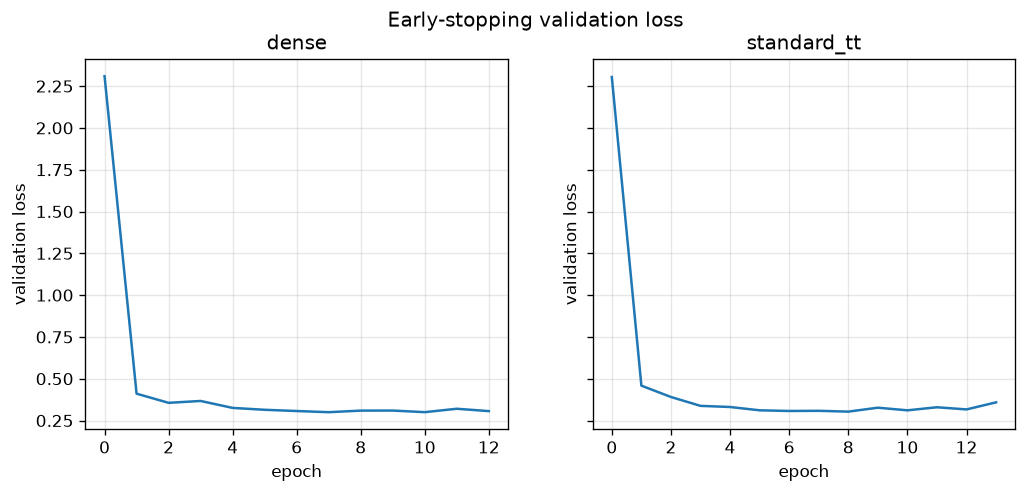

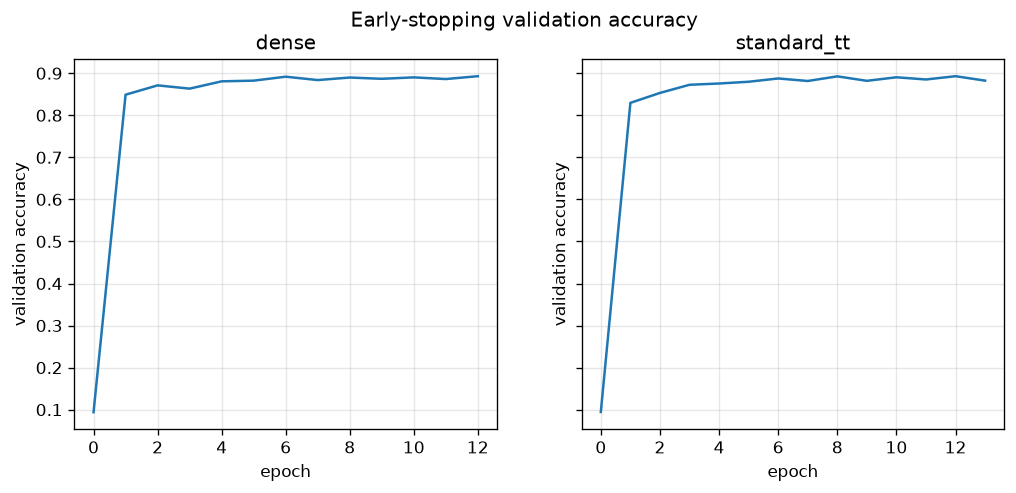

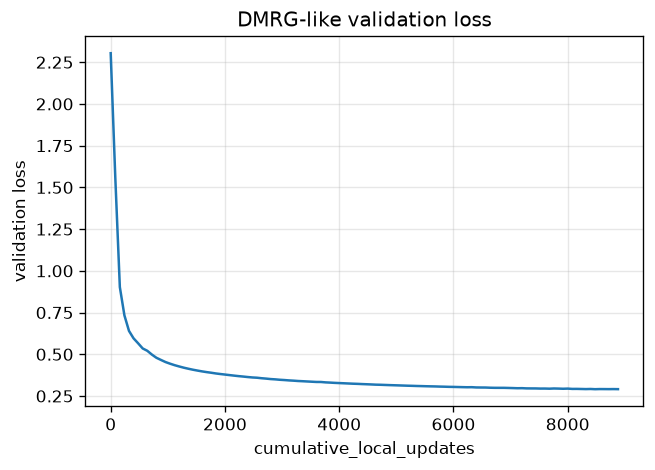

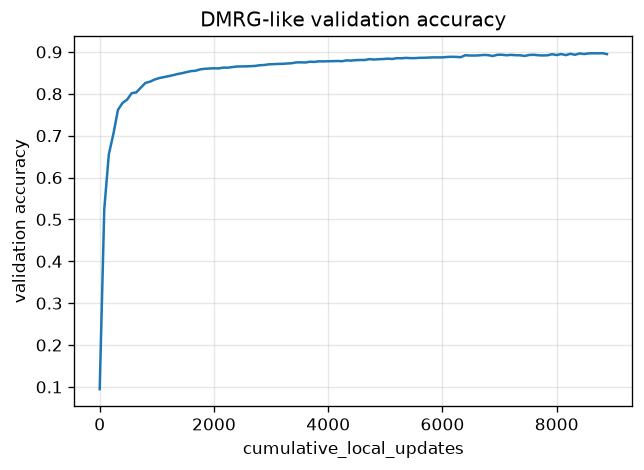

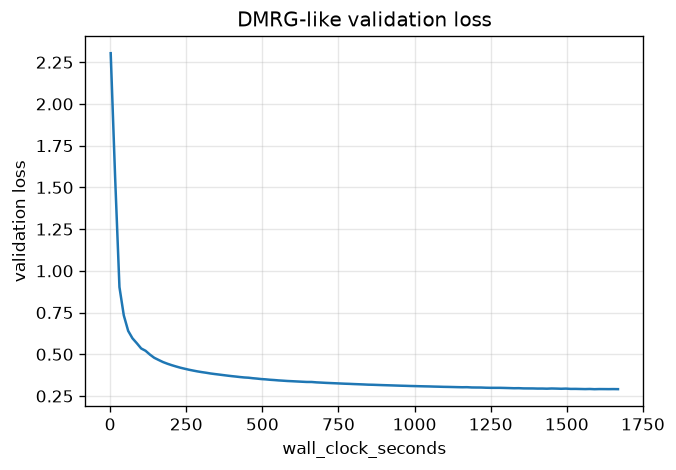

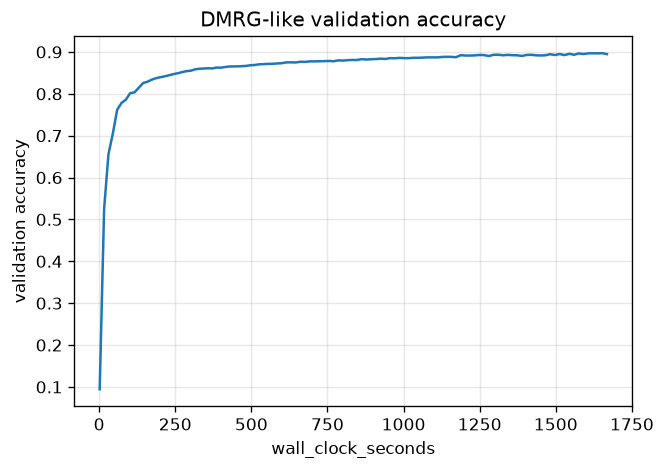

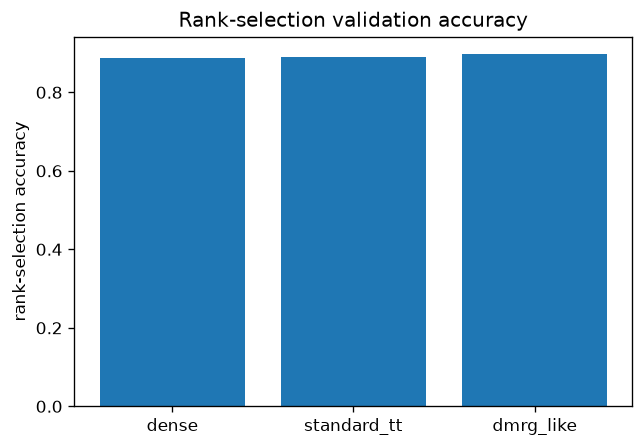

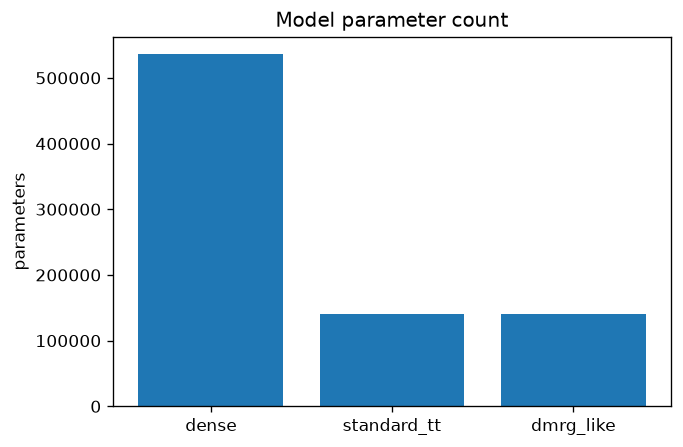

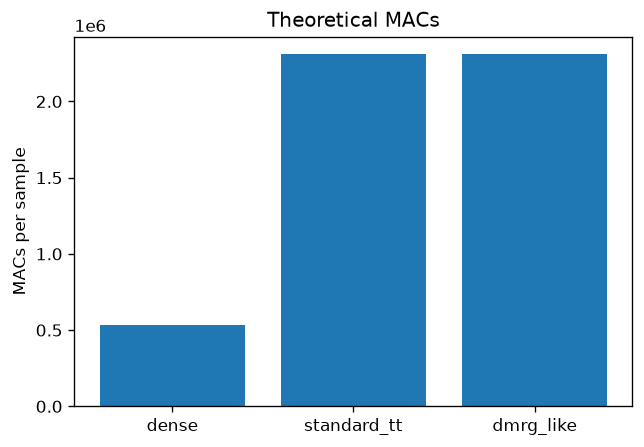

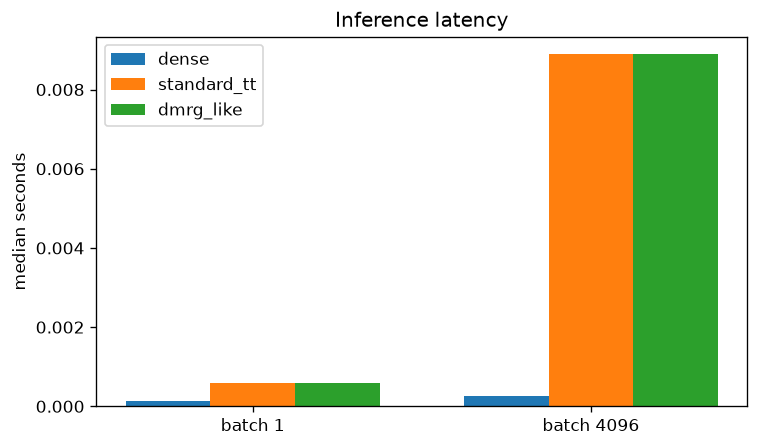

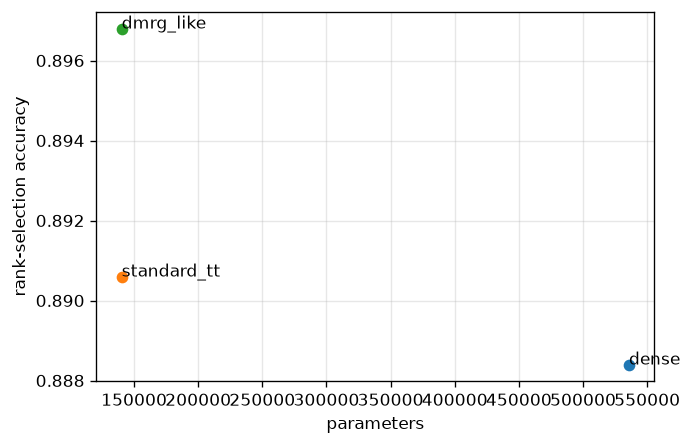

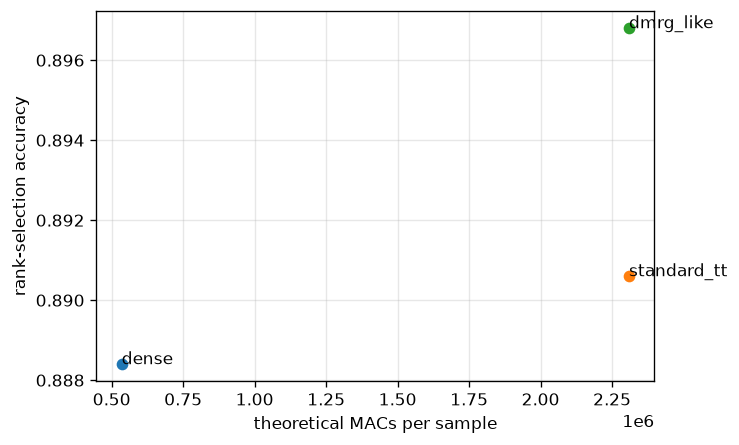

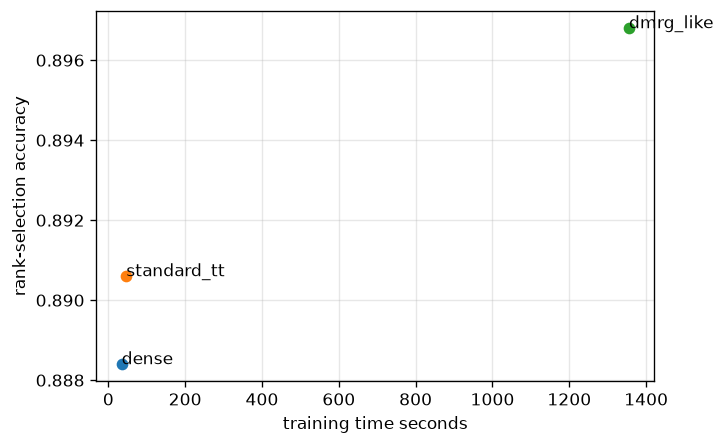

figures: D:\dev\nn-compression-svd-dmrg\results\40_dmrg\10_fashion_mnist_mlp\06_dense_tt_dmrg_like_convergence_comparison\figures
主表: D:\dev\nn-compression-svd-dmrg\results\40_dmrg\10_fashion_mnist_mlp\06_dense_tt_dmrg_like_convergence_comparison\comparison_summary.csv


,condition,stop_reason,best_epoch,best_sweep,best_update,total_optimizer_steps,total_local_updates,train_full_dataset_gradient_passes,train_evaluation_passes,validation_evaluation_passes,early_stopping_validation_loss,early_stopping_validation_accuracy,rank_selection_validation_loss,rank_selection_validation_accuracy,accuracy_minus_dense,loss_improvement_from_dense,actual_ranks,fixed_actual_rank,comparison_label,tt_core_elements,total_model_parameters,parameter_reduction,compression_ratio,theoretical_fc1_macs,theoretical_total_macs,mac_ratio_vs_dense,mac_reduction_vs_dense,training_time_seconds,evaluation_time_seconds,save_time_seconds,peak_training_gpu_allocated_bytes
0,dense,early_stopping,7.0,NaN,NaN,9384,NaN,12,13,13,0.299885,0.8838,0.310588,0.8884,0.0000,0.000000,NaN,True,fixed_actual_rank,0,535818,0.000000,1.000000,401408,535040,1.000000,0.000000,34.792796,24.422209,3.084134,80464384
1,standard_tt,early_stopping,8.0,NaN,NaN,10166,NaN,13,14,14,0.303265,0.8926,0.309005,0.8906,0.0022,0.001582,1|8|12|12|12|12|1,True,fixed_actual_rank,5968,140378,0.738012,3.816966,2175488,2309120,4.315789,-3.315789,46.694169,24.212313,2.731896,187653120
2,dmrg_like,early_stopping,NaN,106.0,8480.0,8880,8880.0,8880,183,184,0.290853,0.8950,0.286605,0.8968,0.0084,0.023982,1|8|12|12|12|12|1,True,fixed_actual_rank,5968,140378,0.738012,3.816966,2175488,2309120,4.315789,-3.315789,1355.376064,312.936606,29.645858,1359745024


,condition,batch_size,median_seconds,q1_seconds,q3_seconds,warmup,repetitions,inference_peak_allocated_bytes,gpu_name,torch,cuda,cudnn,allow_tf32_matmul,allow_tf32_cudnn,cudnn_deterministic,compile,execution
0,dense,1,0.000139,0.000131,0.000163,20,100,70417408,NVIDIA GeForce RTX 5070 Ti,2.11.0+cu128,12.8,91900,False,True,True,False,eager
1,dense,4096,0.000262,0.000260,0.000274,20,100,100032000,NVIDIA GeForce RTX 5070 Ti,2.11.0+cu128,12.8,91900,False,True,True,False,eager
2,standard_tt,1,0.000598,0.000577,0.000636,20,100,69061120,NVIDIA GeForce RTX 5070 Ti,2.11.0+cu128,12.8,91900,False,True,True,False,eager
3,standard_tt,4096,0.008889,0.008871,0.008919,20,100,1006520832,NVIDIA GeForce RTX 5070 Ti,2.11.0+cu128,12.8,91900,False,True,True,False,eager
4,dmrg_like,1,0.000586,0.000564,0.000606,20,100,69061120,NVIDIA GeForce RTX 5070 Ti,2.11.0+cu128,12.8,91900,False,True,True,False,eager
5,dmrg_like,4096,0.008890,0.008869,0.008922,20,100,1006520832,NVIDIA GeForce RTX 5070 Ti,2.11.0+cu128,12.8,91900,False,True,True,False,eager


In [56]:
from pathlib import Path
import csv
import json
import os

if "results_dir" not in globals() or "models_dir" not in globals():
    for _candidate in [Path.cwd(), *Path.cwd().parents]:
        if (_candidate / ".git").exists() and (_candidate / "src").exists():
            _project_root = _candidate
            break
    else:
        raise FileNotFoundError("プロジェクトルートを特定できませんでした。")
    _experiment = "06_dense_tt_dmrg_like_convergence_comparison"
    models_dir = _project_root / "models" / "40_dmrg" / "10_fashion_mnist_mlp" / _experiment
    results_dir = _project_root / "results" / "40_dmrg" / "10_fashion_mnist_mlp" / _experiment
if "CONDITIONS" not in globals():
    CONDITIONS = ("dense", "standard_tt", "dmrg_like")
if "FINISHED_STOPS" not in globals():
    FINISHED_STOPS = {"early_stopping", "max_epochs", "max_sweeps"}
if "LATENCY_BATCH_SIZES" not in globals():
    LATENCY_BATCH_SIZES = (1, 4096)
if "read_csv" not in globals():
    def read_csv(path):
        with Path(path).open(encoding="utf-8", newline="") as handle:
            return list(csv.DictReader(handle))
if "figure_temporary_path" not in globals():
    def figure_temporary_path(path):
        path = Path(path)
        return path.with_name(f"{path.stem}.tmp{path.suffix}")
if "assert_output_path" not in globals():
    def assert_output_path(path):
        resolved = Path(path).resolve()
        allowed = {Path(models_dir).resolve(), Path(results_dir).resolve()}
        if not any(resolved == root or root in resolved.parents for root in allowed):
            raise RuntimeError(f"06 の保存先の外です: {resolved}")
if "atomic_replace" not in globals():
    def atomic_replace(temporary, path):
        assert_output_path(path)
        os.replace(temporary, path)

DMRG_X_AXES = (
    "cumulative_local_updates",
    "wall_clock_seconds",
)
SUMMARY_PATH = results_dir / "comparison_summary.csv"
LATENCY_PATH = results_dir / "latency.csv"


def number(text):
    if text is None or text == "":
        return None
    return float(text)


def load_completed_results():
    missing = []
    if not SUMMARY_PATH.is_file() or not LATENCY_PATH.is_file():
        missing.append("summary_or_latency")
    histories = {}
    for condition in CONDITIONS:
        path = models_dir / condition / "history.csv"
        state_path = models_dir / condition / "run_state.json"
        if not path.is_file() or not state_path.is_file():
            missing.append(condition)
            continue
        state = json.loads(state_path.read_text(encoding="utf-8"))
        if state.get("stop_reason") not in FINISHED_STOPS:
            missing.append(condition + ":" + str(state.get("stop_reason")))
        histories[condition] = read_csv(path)
    if missing:
        return None
    return {
        "summary": read_csv(SUMMARY_PATH),
        "latency": read_csv(LATENCY_PATH),
        "histories": histories,
    }


def write_figures(bundle):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    figures_dir = results_dir / "figures"
    figures_dir.mkdir(parents=True, exist_ok=True)
    assert_output_path(figures_dir)

    def save_figure(fig, name):
        from IPython.display import Image, display
        path = figures_dir / name
        temporary = figure_temporary_path(path)
        assert_output_path(temporary)
        fig.savefig(temporary, dpi=120, bbox_inches="tight", format="png")
        atomic_replace(temporary, path)
        display(Image(filename=str(path)))
        plt.close(fig)

    epoch_conditions = ("dense", "standard_tt")
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    for axis, condition in zip(axes, epoch_conditions):
        rows = bundle["histories"][condition]
        axis.plot([int(row["epoch"]) for row in rows], [float(row["early_stopping_validation_loss"]) for row in rows])
        axis.set_title(condition)
        axis.set_xlabel("epoch")
        axis.set_ylabel("validation loss")
        axis.grid(True, alpha=0.3)
    fig.suptitle("Early-stopping validation loss")
    save_figure(fig, "validation_loss_by_epoch.png")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    for axis, condition in zip(axes, epoch_conditions):
        rows = bundle["histories"][condition]
        axis.plot([int(row["epoch"]) for row in rows], [float(row["early_stopping_validation_accuracy"]) for row in rows])
        axis.set_title(condition)
        axis.set_xlabel("epoch")
        axis.set_ylabel("validation accuracy")
        axis.grid(True, alpha=0.3)
    fig.suptitle("Early-stopping validation accuracy")
    save_figure(fig, "validation_accuracy_by_epoch.png")

    dmrg_rows = bundle["histories"]["dmrg_like"]
    for axis_name in DMRG_X_AXES:
        fig, axis = plt.subplots(figsize=(6, 4))
        axis.plot([float(row[axis_name]) for row in dmrg_rows], [float(row["early_stopping_validation_loss"]) for row in dmrg_rows])
        axis.set_title("DMRG-like validation loss")
        axis.set_xlabel(axis_name)
        axis.set_ylabel("validation loss")
        axis.grid(True, alpha=0.3)
        save_figure(fig, f"validation_loss_dmrg_{axis_name}.png")
        fig, axis = plt.subplots(figsize=(6, 4))
        axis.plot([float(row[axis_name]) for row in dmrg_rows], [float(row["early_stopping_validation_accuracy"]) for row in dmrg_rows])
        axis.set_title("DMRG-like validation accuracy")
        axis.set_xlabel(axis_name)
        axis.set_ylabel("validation accuracy")
        axis.grid(True, alpha=0.3)
        save_figure(fig, f"validation_accuracy_dmrg_{axis_name}.png")

    summary = bundle["summary"]
    labels = [row["condition"] for row in summary]
    fig, axis = plt.subplots(figsize=(6, 4))
    axis.bar(labels, [float(row["rank_selection_validation_accuracy"]) for row in summary])
    axis.set_ylabel("rank-selection accuracy")
    axis.set_title("Rank-selection validation accuracy")
    save_figure(fig, "rank_selection_accuracy.png")

    fig, axis = plt.subplots(figsize=(6, 4))
    axis.bar(labels, [float(row["total_model_parameters"]) for row in summary])
    axis.set_ylabel("parameters")
    axis.set_title("Model parameter count")
    save_figure(fig, "parameter_counts.png")

    fig, axis = plt.subplots(figsize=(6, 4))
    axis.bar(labels, [float(row["theoretical_total_macs"]) for row in summary])
    axis.set_ylabel("MACs per sample")
    axis.set_title("Theoretical MACs")
    save_figure(fig, "theoretical_macs.png")

    fig, axis = plt.subplots(figsize=(7, 4))
    latency = bundle["latency"]
    positions = range(len(LATENCY_BATCH_SIZES))
    width = 0.25
    for index, condition in enumerate(CONDITIONS):
        values = [
            float(next(row["median_seconds"] for row in latency if row["condition"] == condition and int(row["batch_size"]) == batch_size))
            for batch_size in LATENCY_BATCH_SIZES
        ]
        axis.bar([position + index * width for position in positions], values, width=width, label=condition)
    axis.set_xticks([position + width for position in positions])
    axis.set_xticklabels([f"batch {batch_size}" for batch_size in LATENCY_BATCH_SIZES])
    axis.set_ylabel("median seconds")
    axis.set_title("Inference latency")
    axis.legend()
    save_figure(fig, "inference_latency.png")

    def scatter(x_key, xlabel, name):
        fig, axis = plt.subplots(figsize=(6, 4))
        for row in summary:
            axis.scatter(float(row[x_key]), float(row["rank_selection_validation_accuracy"]))
            axis.annotate(row["condition"], (float(row[x_key]), float(row["rank_selection_validation_accuracy"])))
        axis.set_xlabel(xlabel)
        axis.set_ylabel("rank-selection accuracy")
        axis.grid(True, alpha=0.3)
        save_figure(fig, name)

    scatter("total_model_parameters", "parameters", "accuracy_vs_parameters.png")
    scatter("theoretical_total_macs", "theoretical MACs per sample", "accuracy_vs_macs.png")
    scatter("training_time_seconds", "training time seconds", "accuracy_vs_training_time.png")
    print("figures:", figures_dir)


completed = load_completed_results()
if completed is None:
    print("SKIP: 主実験の完了ファイルがそろっていません。図と主表は作りません。")
else:
    write_figures(completed)
    print("主表:", SUMMARY_PATH)
    import pandas as pd
    from IPython.display import display
    with pd.option_context("display.max_columns", None, "display.max_rows", None, "display.width", None):
        display(pd.read_csv(SUMMARY_PATH))
        display(pd.read_csv(LATENCY_PATH))


## 10. 結果を読むときの限界

結果が出たあとも、次の範囲を超えて読まない。

- 通常 TT と DMRG-like は optimizer と更新単位が違う。差は、選んだ学習手順全体の差である。
- parameter 削減は TT 表現と rank 制約による。DMRG-like はその圧縮モデルの学習方法である。
- parameter 数が少ないことは、MACs が少ないことを保証しない。現在の直接縮約では、理論 MACs は Dense より多い。
- 理論 MACs と実測 latency は同じ量ではない。
- early stopping は、数学的収束や大域最適解を保証しない。`max_epochs` と `max_sweeps` は安全上限であり、収束済みではない。
- seed は 1 つなので、一般化した結論にはしない。
- test は使っていない。
- 学習率は、各方式で個別に最適化した値ではない。

数値の優劣は、主表と図が保存されたあとに、そのファイルから読む。この Markdown には、未実行の結果を埋めていない。